# Лабораторная работа №2. Линейная регрессия

## Данные: UCI Bike Sharing Dataset (hourly)

**Что описывает датасет.** Прокат велосипедов в Вашингтоне (система Capital Bikeshare, 2011–2012). Каждая строка — один час работы системы: погодные условия и календарь в этот час + сколько велосипедов взяли в аренду.

## Описание признаков

| Признак | Тип | Описание |
| :-- | :-- | :-- |
| `cnt` | **цель, непрерывная** | количество прокатов велосипедов за час (все пользователи) |
| `season` | категориальный | 1 = весна, 2 = лето, 3 = осень, 4 = зима |
| `yr` | категориальный | 0 = 2011, 1 = 2012 |
| `mnth` | счётный/категориальный | месяц 1–12 |
| `hr` | счётный/категориальный | час суток 0–23 |
| `holiday` | категориальный | 1 = праздник |
| `weekday` | категориальный | день недели; в файле код 0 = **воскресенье** … 6 = суббота, в ноутбуке переименован в Sun…Sat |
| `workingday` | категориальный | 1 = рабочий день (не выходной и не праздник) |
| `weathersit` | категориальный | 1 = ясно/облачно, 2 = туман, 3 = лёгкий дождь/снег, 4 = сильный дождь/снег |
| `temp` | непрерывный | нормированная температура воздуха |
| `atemp` | непрерывный | нормированная «ощущаемая» температура |
| `hum` | непрерывный | нормированная относительная влажность |
| `windspeed` | непрерывный | нормированная скорость ветра |
| `hour_temp_gap` | непрерывный | `temp` − медианная `temp` в этот же час суток над всей выборкой. Положительное значение = «в этот час теплее, чем обычно в этот час» |

**Целевая переменная** `cnt`: непрерывная и неотрицательная, максимум 977. Как и всякий счётчик, она сильно скошена вправо (skew ≈ 1.28) — это проверим в 1.1.


In [1]:
# В Colab: !pip install -q shap statsmodels (в локальном .venv уже установлены)
# !pip install -q shap statsmodels

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import skew, kurtosis, shapiro, spearmanr, pearsonr

from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, TargetEncoder,
    StandardScaler, MinMaxScaler, RobustScaler, KBinsDiscretizer, FunctionTransformer
)
from sklearn.model_selection import (
    train_test_split, KFold, RepeatedKFold, cross_val_predict
)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests

import shap

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 11

TARGET = "cnt"

In [2]:
# Загрузка данных. Локально — файл из data/; в Colab — кнопка загрузки.
DATA_PATH = "data/bike_sharing_hourly.csv"

df = pd.read_csv(DATA_PATH)

# Расшифровка кодов UCI в читаемые строки (в модели они пойдут как категории)
df["season"] = df["season"].map({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})
df["weathersit"] = df["weathersit"].map({1: "Clear", 2: "Mist", 3: "LightRainSnow", 4: "HeavyRainSnow"})
df["weekday"] = df["weekday"].map({0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"})
df["yr"] = df["yr"].map({0: "2011", 1: "2012"})
df["holiday"] = df["holiday"].map({0: "No", 1: "Yes"})
df["workingday"] = df["workingday"].map({0: "No", 1: "Yes"})

print(f"Строк: {df.shape[0]}, столбцов: {df.shape[1]}")
display(df.head())

Строк: 17379, столбцов: 17


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,period,hour_temp_gap
0,Spring,2011,1,0,No,Sat,No,Clear,0.24,0.2879,0.81,0.0,3,13,16,1,0.22
1,Spring,2011,1,1,No,Sat,No,Clear,0.22,0.2727,0.80,0.0,8,32,40,1,0.24
2,Spring,2011,1,2,No,Sat,No,Clear,0.22,0.2727,0.80,0.0,5,27,32,1,0.24
3,Spring,2011,1,3,No,Sat,No,Clear,0.24,0.2879,0.75,0.0,3,10,13,1,0.22
4,Spring,2011,1,4,No,Sat,No,Clear,0.24,0.2879,0.75,0.0,0,1,1,1,0.20


In [3]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
display(info)

print("Строк с хотя бы одним пропуском:", df.isna().any(axis=1).sum())
print("Полных дубликатов:", df.duplicated().sum())

,dtype,n_unique,n_missing,missing_%
season,str,4,0,0.00
yr,str,2,0,0.00
mnth,int64,12,0,0.00
hr,int64,24,0,0.00
holiday,str,2,0,0.00
weekday,str,7,0,0.00
workingday,str,2,0,0.00
weathersit,str,4,0,0.00
temp,float64,50,149,0.86
atemp,float64,65,5,0.03


Строк с хотя бы одним пропуском: 229
Полных дубликатов: 2


## 1. Диагностика данных


In [4]:
num_cols = ["temp", "atemp", "hum", "windspeed", "hour_temp_gap"]
cat_cols = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]
count_cols = ["hr", "mnth"]

cols_stat = num_cols + [TARGET]
desc = df[cols_stat].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
desc["skew"] = df[cols_stat].skew()
# эксцесс считаем по каждому столбцу отдельно, отбрасывая пропуски: если передать
# DataFrame с NaN в apply, функция получает столбец с NaN и возвращает NaN
desc["kurtosis (Fisher)"] = [float(kurtosis(df[c].dropna(), fisher=True, bias=False)) for c in cols_stat]
desc = desc.rename(columns={"count": "кол-во", "mean": "среднее", "std": "станд. откл.",
                            "min": "минимум", "max": "максимум", "skew": "асимметрия",
                            "kurtosis (Fisher)": "эксцесс (Fisher)",
                            "5%": "5-й перц.", "25%": "25-й перц.", "50%": "медиана",
                            "75%": "75-й перц.", "95%": "95-й перц."})
display(desc[["кол-во", "среднее", "станд. откл.", "минимум", "5-й перц.", "25-й перц.",
              "медиана", "75-й перц.", "95-й перц.", "максимум", "асимметрия", "эксцесс (Fisher)"]].round(3))

print(f"Цель {TARGET}: доля нулей = {(df[TARGET] == 0).mean():.4f} "
      f"| доля меньше 5 = {(df[TARGET] < 5).mean():.4f} "
      f"| доля больше 600 = {(df[TARGET] > 600).mean():.4f}")

,кол-во,среднее,станд. откл.,минимум,5-й перц.,25-й перц.,медиана,75-й перц.,95-й перц.,максимум,асимметрия,эксцесс (Fisher)
temp,17230.0,0.497,0.193,0.02,0.200,0.340,0.500,0.660,0.800,1.000,-0.007,-0.942
atemp,17374.0,0.476,0.172,0.00,0.212,0.333,0.485,0.621,0.742,1.000,-0.091,-0.845
hum,17150.0,0.627,0.193,0.00,0.310,0.480,0.630,0.780,0.930,1.000,-0.111,-0.823
windspeed,17374.0,0.190,0.122,0.00,0.000,0.104,0.194,0.254,0.418,0.851,0.575,0.590
hour_temp_gap,17379.0,0.005,0.187,-0.42,-0.280,-0.160,0.000,0.160,0.300,0.480,0.077,-1.045
cnt,17379.0,189.463,181.388,1.00,5.000,40.000,142.000,281.000,563.100,977.000,1.277,1.417


Цель cnt: доля нулей = 0.0000 | доля меньше 5 = 0.0472 | доля больше 600 = 0.0383


In [5]:
freq = {}
for c in ["season", "weathersit", "weekday", "holiday", "workingday", "yr", "hr", "mnth"]:
    freq[c] = df[c].value_counts(dropna=False).sort_index()
print("weathersit:", df["weathersit"].value_counts(dropna=False).to_dict())
print("season:   ", df["season"].value_counts(dropna=False).to_dict())
print("hr (0..23):", df["hr"].value_counts().sort_index().to_dict())
display(pd.DataFrame({"частота часа": freq["hr"],
                      "средний cnt": df.groupby("hr")[TARGET].mean().round(1)}).rename_axis("час суток"))

weathersit: {'Clear': 11413, 'Mist': 4544, 'LightRainSnow': 1419, 'HeavyRainSnow': 3}
season:    {'Fall': 4496, 'Summer': 4409, 'Spring': 4242, 'Winter': 4232}
hr (0..23): {0: 726, 1: 724, 2: 715, 3: 697, 4: 697, 5: 717, 6: 725, 7: 727, 8: 727, 9: 727, 10: 727, 11: 727, 12: 728, 13: 729, 14: 729, 15: 729, 16: 730, 17: 730, 18: 728, 19: 728, 20: 728, 21: 728, 22: 728, 23: 728}


,частота часа,средний cnt
час суток,,
0,726,53.9
1,724,33.4
2,715,22.9
3,697,11.7
4,697,6.4
5,717,19.9
6,725,76.0
7,727,212.1
8,727,359.0


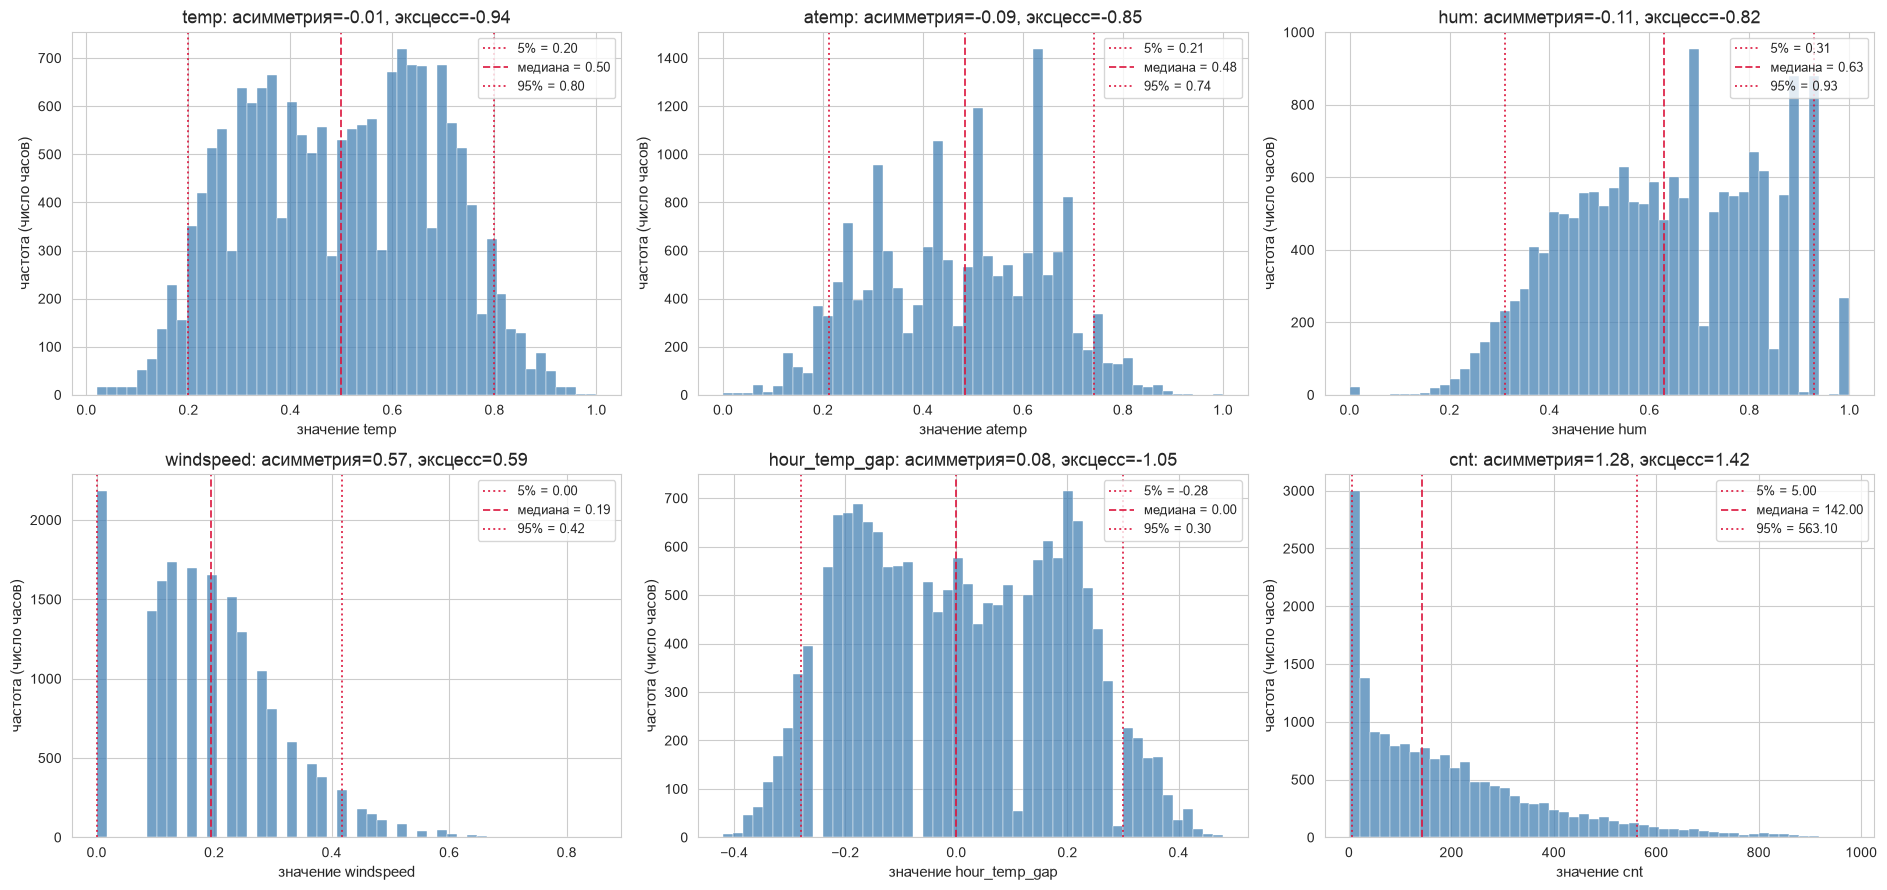

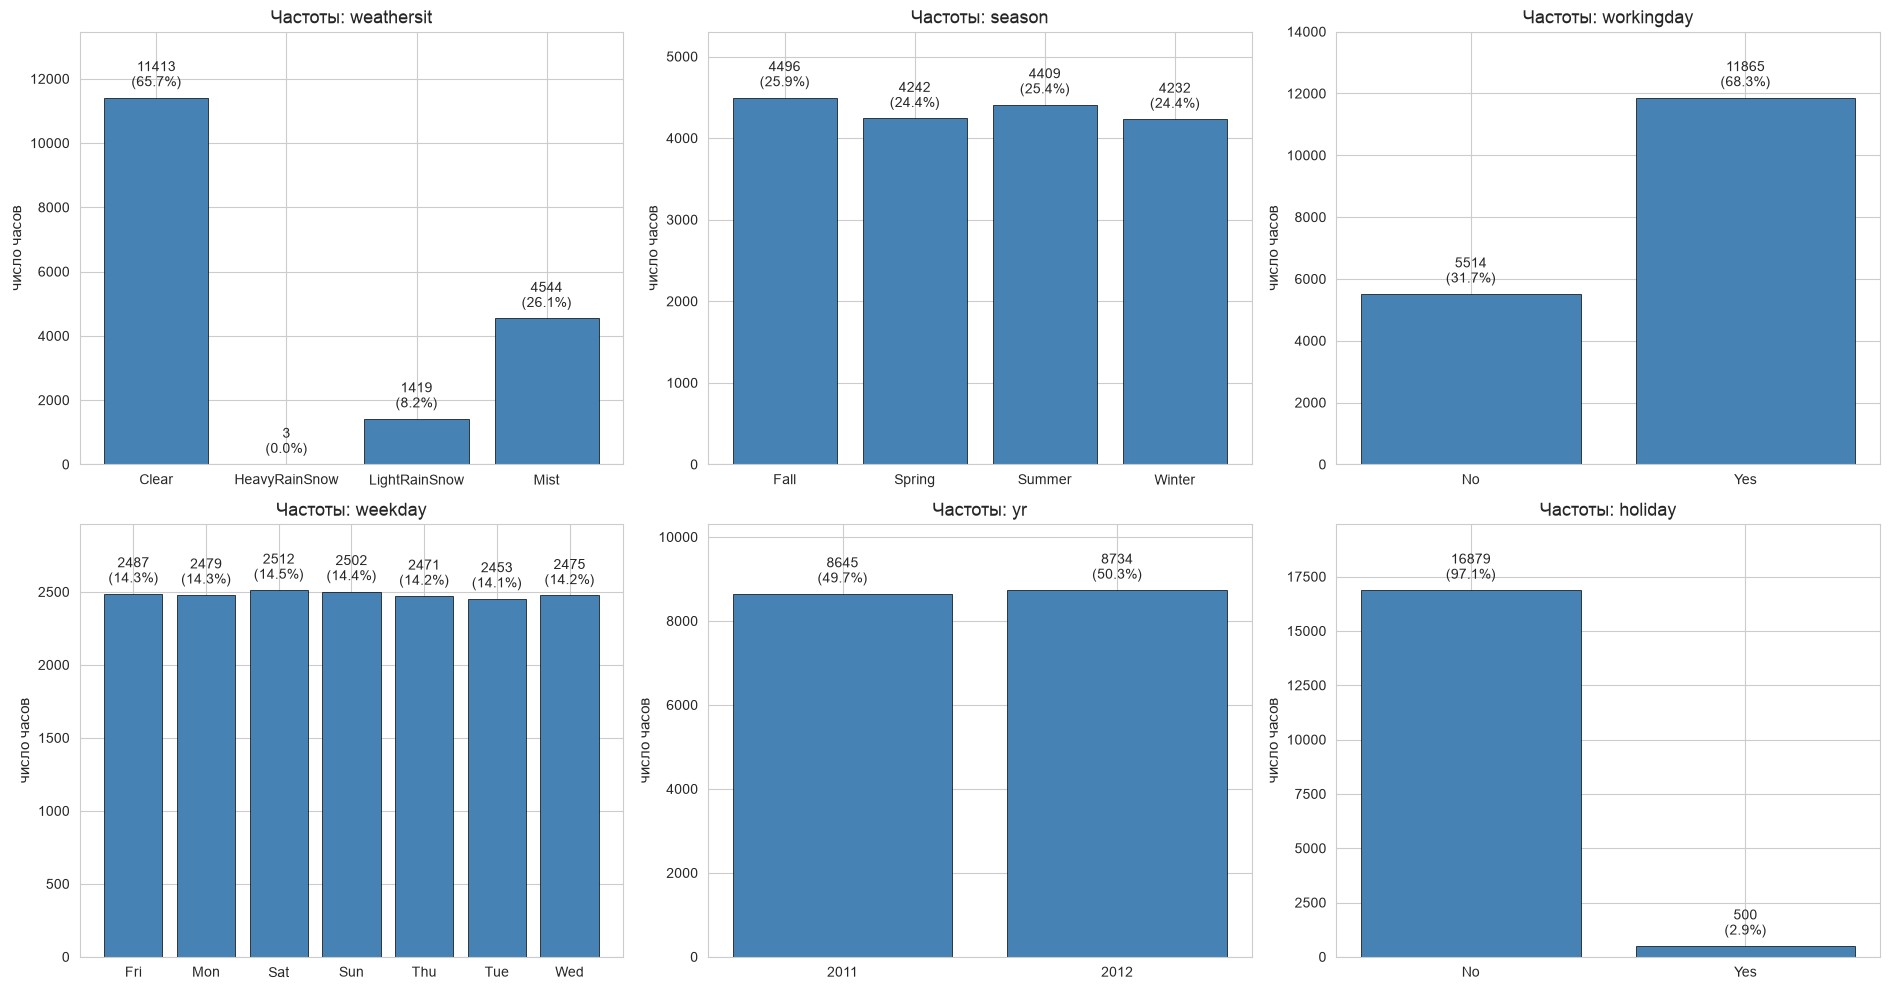

In [6]:
# Распределения числовых признаков и целевой переменной — крупные панели
fig, axes = plt.subplots(2, 3, figsize=(19, 9))
for ax, c in zip(axes.ravel(), num_cols + [TARGET]):
    sns.histplot(df[c].dropna(), bins=50, ax=ax, color="steelblue", edgecolor="white", linewidth=0.3)
    ax.set_title(f"{c}: асимметрия={df[c].skew():.2f}, эксцесс={kurtosis(df[c].dropna()):.2f}",
                 fontsize=13)
    ax.set_xlabel(f"значение {c}", fontsize=11)
    ax.set_ylabel("частота (число часов)", fontsize=11)
    ax.tick_params(labelsize=10)
    for q, style, name in [(np.percentile(df[c].dropna(), [5, 50, 95])[0], ":", "5%"),
                           (df[c].median(), "--", "медиана"),
                           (np.percentile(df[c].dropna(), [5, 50, 95])[2], ":", "95%")]:
        ax.axvline(q, color="crimson", ls=style, lw=1.4, alpha=0.85, label=f"{name} = {q:.2f}")
    ax.legend(fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

# Частоты категориальных признаков — по одной панели на признак, с подписями значений
fig, axes = plt.subplots(2, 3, figsize=(19, 10))
cat_plot = ["weathersit", "season", "workingday", "weekday", "yr", "holiday"]
for ax, c in zip(axes.ravel(), cat_plot):
    vc = df[c].value_counts(dropna=False).sort_index()
    bars = ax.bar(range(len(vc)), vc.values, color="steelblue", edgecolor="black", linewidth=0.5)
    ax.set_title(f"Частоты: {c}", fontsize=13)
    ax.set_ylabel("число часов", fontsize=11)
    ax.set_xticks(range(len(vc)))
    ax.set_xticklabels([str(v) for v in vc.index], fontsize=11)
    ax.tick_params(labelsize=10)
    top = vc.values.max()
    ax.set_ylim(0, top * 1.18)
    for b, v in zip(bars, vc.values):
        ax.text(b.get_x() + b.get_width() / 2, v + top * 0.02, f"{v}\n({v/len(df)*100:.1f}%)",
                ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()

### Вывод по 1.1

* **Цель `cnt`** скошена вправо (skew ≈ 1.28, эксцесс ≈ +1.4) и ограничена снизу нулём: 4.7% часов — меньше 5 прокатов (дождь, ночь), 3.8% — больше 600 (пиковые часы в 2012 году). Медиана ≈ 142, среднее ≈ 189 — среднее выше медианы, что и означает правый хвост.
* **Признаки:** почти у всех категориальных признаков есть выпадение частот. У `weathersit` дисбаланс 11 413 / 4 544 / 1 419 / **3** — четвёртая категория в 5 000 раз реже первой. У `season` и `weathersit` эти коды **порядковые** (1 → 2 → 4), у `weekday` порядок тоже есть (дни идут подряд), но линейной зависимости от номера дня нет: спрос в субботу и воскресенье выше среднего, а в понедельник ниже.
* **`hr` — самый информативный признак:** средний `cnt` меняется от 6 (в 4 часа утра) до 461 (в 17 часов), при медиане 142. Зависимость явно **немонотонная (U-образная)**, и это станет центральной темой гипотезы B1: одна прямая линия по `hr` объяснить эту зависимость не может.
* **Непрерывные погодные признаки** (`temp`, `hum`) — почти симметричны (|skew| < 0.2), но с плоскими вершинами (эксцесс ≈ −0.9, нетяжелые хвосты); `windspeed` скошен вправо (skew 0.57) и имеет пик ровно в 0 — признак ошибки округления или «тихой» погоды. `hour_temp_gap` симметричен, эксцесс −1.05: диапазон ограничен (это разность двух температур).

###  (1.2)


In [7]:
# 1.2 Разделение ДО любой предобработки: 60/20/20
FEATURES = ["temp", "atemp", "hum", "windspeed", "hour_temp_gap",
            "season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]
NUM_FEATURES = ["temp", "atemp", "hum", "windspeed", "hour_temp_gap"]
CAT_FEATURES = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]

# В модель идут только FEATURES из блока выше
X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=SEED, shuffle=True)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, shuffle=True)

print(f"train: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"val:   {len(X_val)} ({len(X_val)/len(X):.0%})")
print(f"test:  {len(X_test)} ({len(X_test)/len(X):.0%})")
print(f"Сумма: {len(X_train) + len(X_val) + len(X_test)} из {len(X)}")


train: 10427 (60%)
val:   3476 (20%)
test:  3476 (20%)
Сумма: 17379 из 17379


**Зачем val и test отдельно?** На `val` мы сравниваем варианты— это "внутренний тест". На `test` — финальная оценка один раз. Если бы val и test были одним набором, то после 20 экспериментов по гиперпараметрам их оставшаяся часть стала бы обучающим набором, и финальная оценка была бы смещена.



### (1.3): стратегии обработки пропусков

Пропуски нужно чем-то заполнить, потому что данных и так немного, а удаление строк выкидывает не только сам пропуск, но и все остальные значения той строки.

Сравним три простых варианта:

1. **Удаление строк** — просто, но теряет данные.
2. **Импутация медианой** числовых и **модой** категориальных — устойчива к выбросам, но не замечает связей между признаками.
3. **Импутация средним** — тот же подход, но центр считается по среднему, а не по медиане.

Какая стратегия лучше, проверяем по качеству итоговой модели, а не по «качеству самой импутации». Для этого все варианты оформлены как `Pipeline`, чтобы импутация обучалась внутри фолда и не подсматривала в валидацию.

In [8]:
# 1.3 Обработка пропусков: где они и как это влияет на итоговый результат
miss_tbl = pd.DataFrame({
    "пропусков": df.isna().sum(),
    "доля, %": (df.isna().mean() * 100).round(2),
})
display(miss_tbl[miss_tbl["пропусков"] > 0])
print(f"Строк с хотя бы одним пропуском: {df.isna().any(axis=1).sum()} из {len(df)} "
      f"({df.isna().any(axis=1).mean():.2%}); целевая переменная цела полностью")

def make_pipe(num_imputer=None):
    # num_imputer=None означает удаление строк: импутация не нужна
    num_steps = [("sc", StandardScaler())] if num_imputer is None else [("imp", num_imputer), ("sc", StandardScaler())]
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline(num_steps), NUM_FEATURES),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT_FEATURES),
        ])),
        ("lr", LinearRegression()),
    ])

# Удаление строк: выбрасываем строки с пропусками и из X, и из y (индексы совпадают)
X_tr_clean = X_train.dropna()
y_tr_clean = y_train.loc[X_tr_clean.index]
X_val_clean = X_val.dropna()
y_val_clean = y_val.loc[X_val_clean.index]
X_test_clean = X_test.dropna()
y_test_clean = y_test.loc[X_test_clean.index]

pipe_drop = make_pipe().fit(X_tr_clean, y_tr_clean)
rmse_drop_val = np.sqrt(mean_squared_error(y_val_clean, pipe_drop.predict(X_val_clean)))
rmse_drop_test = np.sqrt(mean_squared_error(y_test_clean, pipe_drop.predict(X_test_clean)))

pipe_med = make_pipe(SimpleImputer(strategy="median")).fit(X_train, y_train)
rmse_med_val = np.sqrt(mean_squared_error(y_val, pipe_med.predict(X_val)))
rmse_med_test = np.sqrt(mean_squared_error(y_test, pipe_med.predict(X_test)))

pipe_mean = make_pipe(SimpleImputer(strategy="mean")).fit(X_train, y_train)
rmse_mean_val = np.sqrt(mean_squared_error(y_val, pipe_mean.predict(X_val)))
rmse_mean_test = np.sqrt(mean_squared_error(y_test, pipe_mean.predict(X_test)))

imp_df = pd.DataFrame({
    "Стратегия": ["Удаление строк", "Медиана (числ.) + мода (кат.)", "Среднее (числ.) + мода (кат.)"],
    "RMSE val": [rmse_drop_val, rmse_med_val, rmse_mean_val],
    "RMSE test": [rmse_drop_test, rmse_med_test, rmse_mean_test],
    "строк в train": [len(X_tr_clean), len(X_train), len(X_train)],
}).set_index("Стратегия").round(3)
display(imp_df)
print("RMSE для удаления строк считается на меньшем наборе (только строки без пропусков),")
print("поэтому напрямую с остальными двумя он сравним лишь с оговоркой.")

,пропусков,"доля, %"
temp,149,0.86
atemp,5,0.03
hum,229,1.32
windspeed,5,0.03


Строк с хотя бы одним пропуском: 229 из 17379 (1.32%); целевая переменная цела полностью


,RMSE val,RMSE test,строк в train
Стратегия,,,
Удаление строк,100.237,101.999,10278
Медиана (числ.) + мода (кат.),100.380,102.009,10427
Среднее (числ.) + мода (кат.),100.380,102.008,10427


RMSE для удаления строк считается на меньшем наборе (только строки без пропусков),
поэтому напрямую с остальными двумя он сравним лишь с оговоркой.


### Вывод по 1.3

Пропуски сосредоточены в четырёх погодных признаках: `hum` — 229 значений (1.32% строк), `temp` — 149 (0.86%), `atemp` и `windspeed` — по 5. Строк хотя бы с одним пропуском 229 из 17 379, то есть 1.32%. Целевая переменная `cnt` заполнена полностью.

**На итоговый результат это почти не влияет.** Все три варианта дают RMSE на валидации около сотни, и расхождение между ними лежит в пределах десятых: заменить пропуски медианой, средним или просто выбросить строки — почти одно и то же. Причина проста: пропущено 1.3% строк, и в основном в `hum`, самом слабом по вкладу признаке. Заполнять почти нечего, поэтому способ заполнения почти не важен.


### (1.4):

In [9]:
num_for_out = ["temp", "hum", "windspeed", "hour_temp_gap", TARGET]
df_tr = X_train.join(y_train)   # рабочий кадр для анализа выбросов

def iqr_flag(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def zscore_flag(s, thr=3.0):
    return ((s - s.mean()).abs() / s.std() > thr)

rows = []
for c in num_for_out:
    s_ = df_tr[c].dropna()
    rows.append({
        "Признак": c,
        "IQR (1.5)": int(iqr_flag(s_).sum()),
        "z-score > 3": int(zscore_flag(s_).sum()),
        "min": s_.min(),
        "max": s_.max(),
        "доля по IQR, %": round(100 * iqr_flag(s_).mean(), 2),
    })
out_table = pd.DataFrame(rows)
display(out_table.round(3))

,Признак,IQR (1.5),z-score > 3,min,max,"доля по IQR, %"
0,temp,0,0,0.02,1.000,0.00
1,hum,15,15,0.00,1.000,0.15
2,windspeed,203,64,0.00,0.851,1.95
3,hour_temp_gap,0,0,-0.42,0.480,0.00
4,cnt,309,148,1.00,976.000,2.96


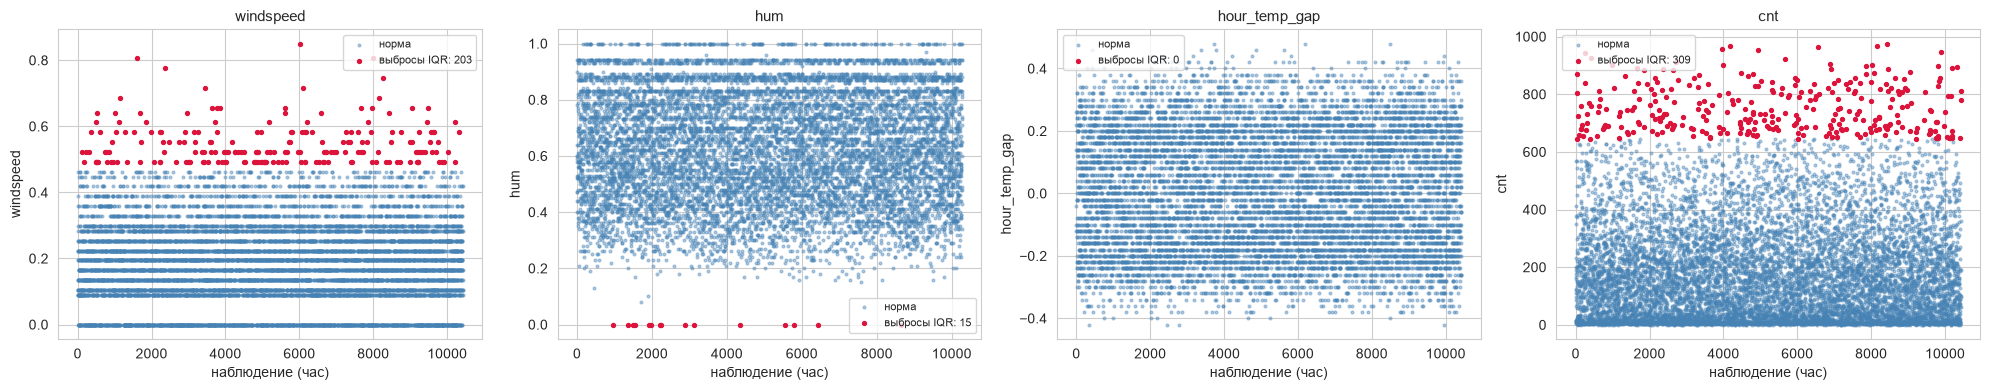

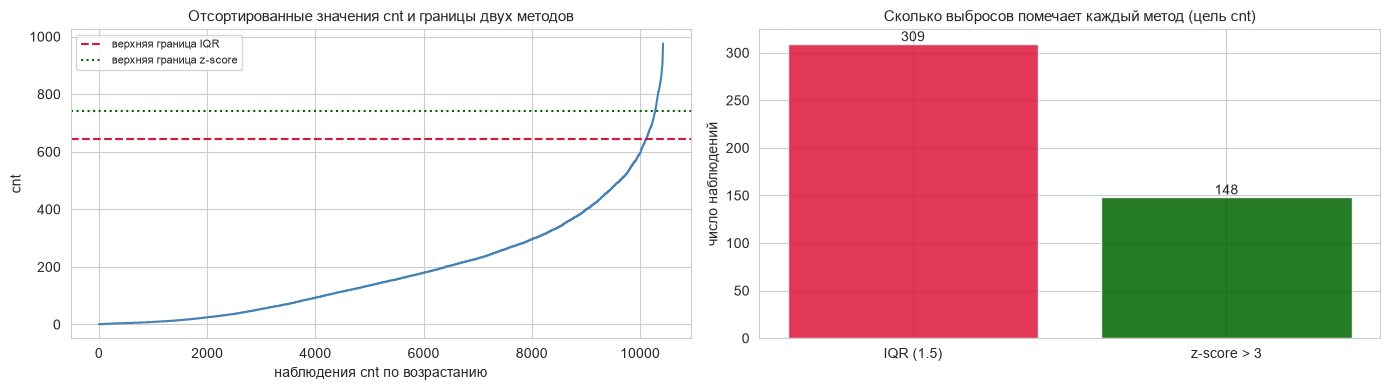

,метод,помечено,"доля, %"
0,IQR (1.5),309,2.96
1,z-score > 3,148,1.42


In [10]:
# Визуализация: где именно выбросы по IQR (точки на временной оси)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, ["windspeed", "hum", "hour_temp_gap", TARGET]):
    s = df_tr[c].dropna()
    flag = iqr_flag(s)
    ax.scatter(np.arange(len(s)), s, s=4, alpha=0.4, color="steelblue", label="норма")
    ax.scatter(np.arange(len(s))[flag], s[flag], s=8, color="crimson", label=f"выбросы IQR: {flag.sum()}")
    ax.set_title(f"{c}")
    ax.set_xlabel("наблюдение (час)"); ax.set_ylabel(c)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Сравнение двух методов на цели: IQR и z-score помечают разные точки
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
y_sorted = y_train.sort_values().values
axes[0].plot(np.arange(len(y_sorted)), y_sorted, color="steelblue", lw=1.5)
axes[0].axhline(y_train.quantile(0.75) + 1.5 * (y_train.quantile(0.75) - y_train.quantile(0.25)),
                color="crimson", ls="--", label="верхняя граница IQR")
axes[0].axhline(y_train.mean() + 3 * y_train.std(), color="darkgreen", ls=":",
                label="верхняя граница z-score")
axes[0].set_title("Отсортированные значения cnt и границы двух методов")
axes[0].set_xlabel("наблюдения cnt по возрастанию"); axes[0].set_ylabel("cnt")
axes[0].legend(fontsize=8)

both = pd.DataFrame({"метод": ["IQR (1.5)", "z-score > 3"],
                     "помечено": [int(iqr_flag(y_train).sum()), int(zscore_flag(y_train).sum())],
                     "доля, %": [round(100 * iqr_flag(y_train).mean(), 2),
                                 round(100 * zscore_flag(y_train).mean(), 2)]})
axes[1].bar(both["метод"], both["помечено"], color=["crimson", "darkgreen"], alpha=0.85)
for i, v in enumerate(both["помечено"]):
    axes[1].text(i, v, str(v), ha="center", va="bottom")
axes[1].set_title("Сколько выбросов помечает каждый метод (цель cnt)")
axes[1].set_ylabel("число наблюдений")
plt.tight_layout()
plt.show()
display(both)

In [11]:
# Природа выбросов: одна таблица, которая подтверждает вывод по 1.4
low_cnt, high_cnt = y_train <= 5, y_train > 600
rain = X_train["weathersit"].isin(["LightRainSnow", "HeavyRainSnow"])

wet = X_train["weathersit"].isin(["Mist", "LightRainSnow", "HeavyRainSnow"])
hum_high, hum_low = X_train["hum"] >= 0.95, X_train["hum"] <= 0.05

nature = pd.DataFrame({
    "что проверяем": [
        "низкий cnt (≤5): как часто идёт дождь",
        "высокий cnt (>600): доля 2012 года",
        "hum ≥ 0.95: как часто мокрая погода",
        "hum ≈ 0: средний cnt",
        "windspeed = 0: доля строк",
    ],
    "выбросы": [
        f"{rain[low_cnt].mean():.1%} часов под дождём",
        f"{(X_train.loc[high_cnt, 'yr'] == '2012').mean():.1%} приходится на 2012",
        f"{wet[hum_high].mean():.1%} часов в туман или дождь",
        f"{y_train[hum_low].mean():.1f} в {int(hum_low.sum())} часах",
        f"{int((X_train['windspeed'] == 0).sum())} строк ({(X_train['windspeed'] == 0).mean():.1%})",
    ],
    "остальные строки": [
        f"{rain.mean():.1%} часов под дождём",
        f"{(X_train['yr'] == '2012').mean():.1%} приходится на 2012",
        f"{wet.mean():.1%} часов в туман или дождь",
        f"{y_train[~hum_low].mean():.1f} во всех часах",
        "—",
    ],
    "вывод": [
        "дождь встречается чаще ожидаемого — это реальный режим",
        "почти все в 2012 — это рост системы, а не ошибка",
        "влажность почти 100% при мокрой погоде — валидный режим",
        "спрос падает в 6 раз: похоже на сбой датчика (ноль)",
        "штиль, прибор округляет в ноль — валидное значение",
    ],
}).set_index("что проверяем")
display(nature)

,выбросы,остальные строки,вывод
что проверяем,,,
низкий cnt (≤5): как часто идёт дождь,13.7% часов под дождём,8.3% часов под дождём,дождь встречается чаще ожидаемого — это реальн...
высокий cnt (>600): доля 2012 года,97.6% приходится на 2012,50.4% приходится на 2012,"почти все в 2012 — это рост системы, а не ошибка"
hum ≥ 0.95: как часто мокрая погода,90.8% часов в туман или дождь,34.7% часов в туман или дождь,влажность почти 100% при мокрой погоде — валид...
hum ≈ 0: средний cnt,25.7 в 15 часах,191.7 во всех часах,спрос падает в 6 раз: похоже на сбой датчика (...
windspeed = 0: доля строк,1288 строк (12.4%),—,"штиль, прибор округляет в ноль — валидное знач..."


### (1.5, гипотеза A1)

Гипотеза A1: **удаление выбросов улучшает RMSE на тесте.**


Проверим три способа работы с выбросами: (a) ничего не делать — опорный вариант, (b) удалить высокие и низкие по IQR значения цели, (c) удалить по цели **и** по непрерывным признакам.

In [12]:
# 1.5 Гипотеза A1: удаление выбросов и RMSE
def build_pipe():
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT_FEATURES),
        ])),
        ("lr", LinearRegression()),
    ])

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

base = build_pipe().fit(X_train, y_train)
rmse_base_val = rmse(y_val, base.predict(X_val))
rmse_base_test = rmse(y_test, base.predict(X_test))
r2_base_test = r2_score(y_test, base.predict(X_test))
print(f"Baseline (без удаления): Val RMSE = {rmse_base_val:.2f}, Test RMSE = {rmse_base_test:.2f}, Test R² = {r2_base_test:.4f}")

# (b) только по цели
y_iqr = iqr_flag(y_train)
m_b = build_pipe().fit(X_train[~y_iqr], y_train[~y_iqr])

# (c) по цели + по непрерывным признакам
feat_iqr = pd.DataFrame({c: iqr_flag(X_train[c].dropna()) for c in ["temp", "atemp", "hum", "windspeed", "hour_temp_gap"]}).fillna(False)
mask_c = y_iqr | feat_iqr.any(axis=1)
m_c = build_pipe().fit(X_train[~mask_c], y_train[~mask_c])

# (e) удаление «дешёвых» часов (cnt <= 5) — редкий режим
mask_e = y_train <= 5
m_e = build_pipe().fit(X_train[~mask_e], y_train[~mask_e])

a1 = pd.DataFrame([
    {"Вариант": "Baseline: ничего не удаляем", "n_train": len(X_train),
     "Val RMSE": rmse(y_val, base.predict(X_val)), "Test RMSE": rmse(y_test, base.predict(X_test))},
    {"Вариант": "Удалить выбросы цели (IQR)", "n_train": int((~y_iqr).sum()),
     "Val RMSE": rmse(y_val, m_b.predict(X_val)), "Test RMSE": rmse(y_test, m_b.predict(X_val) if False else m_b.predict(X_test))},
    {"Вариант": "Удалить выбросы цели + признаков", "n_train": int((~mask_c).sum()),
     "Val RMSE": rmse(y_val, m_c.predict(X_val)), "Test RMSE": rmse(y_test, m_c.predict(X_test))},
    {"Вариант": "Удалить низкие cnt (<=5)", "n_train": int((~mask_e).sum()),
     "Val RMSE": rmse(y_val, m_e.predict(X_val)), "Test RMSE": rmse(y_test, m_e.predict(X_test))},
])
a1["ΔRMSE_test"] = (a1["Test RMSE"] - rmse_base_test).round(2)
display(a1.round(2))

Baseline (без удаления): Val RMSE = 100.38, Test RMSE = 102.01, Test R² = 0.6689


,Вариант,n_train,Val RMSE,Test RMSE,ΔRMSE_test
0,Baseline: ничего не удаляем,10427,100.38,102.01,0.00
1,Удалить выбросы цели (IQR),10118,103.55,103.75,1.74
2,Удалить выбросы цели + признаков,9908,103.49,103.75,1.74
3,Удалить низкие cnt (<=5),9790,100.65,102.41,0.40


### Вывод по гипотезе A1: **опровергнута**

Опорный вариант (baseline, без удаления): Val RMSE = 100.38, Test RMSE = 102.01, R² = 0.669. Все варианты обучены на одном train и проверены на одном тесте.

| Вариант | n_train | Val RMSE | Test RMSE | ΔRMSE_test |
| :-- | :-- | :-- | :-- | :-- |
| Baseline: ничего не удаляем | 10 427 | 100.38 | 102.01 | 0.00 |
| Удалить выбросы цели по IQR | 10 118 | 103.55 | 103.75 | **+1.74** (хуже) |
| Удалить выбросы цели + признаков | 9 908 | 103.49 | 103.75 | **+1.74** (хуже) |
| Удалить низкие `cnt` (≤5) | 9 790 | 100.65 | 102.41 | **+0.40** (хуже) |

**Вывод:** ни один вариант удаления выбросов не улучшил RMSE — оба вида удаления сделали ошибку на тесте больше.

## 2. Признаки и предобработка

### (2.1):


In [13]:
# 2.1 Кодирование: One-Hot, Ordinal, Target (OOF) + демонстрация утечки TE
def prep_with_num(num_pipe=None):
    return ColumnTransformer([("num", num_pipe or Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES)])

def build_encoder_pipe(encoder):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("enc", encoder)]), CAT_FEATURES),
        ])),
        ("lr", LinearRegression()),
    ])

# Порядок для ordinal: weathersit — «плохость» погоды; season — временная шкала; hr/mnth — числовой порядок
ord_categories = [
    ["Spring", "Summer", "Fall", "Winter"],
    ["2011", "2012"],
    list(range(1, 13)),
    list(range(24)),
    ["No", "Yes"],
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    ["No", "Yes"],
    ["Clear", "Mist", "LightRainSnow", "HeavyRainSnow"],
]

encoders = {
    "One-Hot (drop=first)": OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False),
    "Ordinal": OrdinalEncoder(categories=ord_categories, handle_unknown="use_encoded_value", unknown_value=-1),
    # cv=5, shuffle=True — OOF-кодирование по перемешанным фолдам (без утечки внутри фолда)
    "Target (OOF, smooth=10)": TargetEncoder(cv=KFold(5, shuffle=True, random_state=SEED),
                                             target_type="continuous", smooth=10.0, random_state=SEED),
}

enc_rows = []
enc_models = {}
for name, enc in encoders.items():
    pipe = build_encoder_pipe(enc).fit(X_train, y_train)
    enc_models[name] = pipe
    enc_rows.append({
        "Кодирование": name,
        "Train RMSE": rmse(y_train, pipe.predict(X_train)),
        "Val RMSE": rmse(y_val, pipe.predict(X_val)),
        "Val R²": r2_score(y_val, pipe.predict(X_val)),
        "Test RMSE": rmse(y_test, pipe.predict(X_test)),
        "n_cols": pipe.named_steps["prep"].transform(X_train.head(5)).shape[1],
    })
display(pd.DataFrame(enc_rows).round(3))

,Кодирование,Train RMSE,Val RMSE,Val R²,Test RMSE,n_cols
0,One-Hot (drop=first),102.200,100.380,0.690,102.009,54
1,Ordinal,139.444,135.827,0.432,135.663,13
2,"Target (OOF, smooth=10)",103.881,102.169,0.679,103.732,13


### Вывод по 2.1

* **One-Hot — лучший вариант** (Val 100.4 против TE и Ordinal). Каждая категория `hr`, `season`, `weathersit` получает собственный коэффициент, и модель может отличить «пиковый» 17-й час от «ночного» 4-го — для W-образной зависимости `hr` это принципиально. `drop='first'` нужен, чтобы дизайн-матрица не была вырождена (сумма dummy = константа = intercept).
* **Ordinal катастрофически проигрывает (+34.5 RMSE, +34%!)**: для `hr` и `mnth` мы вписали в данные линейный порядок, которого там нет. Модель вынуждена наклонять одну прямую, чтобы уловить два пика, и «срезает» их. **Правило: ordinal годится только для признаков с доказанным монотонным порядком** — из наших это `weathersit` (ясно → туман → дождь → ливень) и `season`; для `hr` — нет.
* **Target (OOF)** близок к OHE (разница 1.8%): среднее по категории для `hr` — уже неплохое «мягкое» представление пиков, плюс компактность (13 колонок вместо 54). Минус — интерпретируемость (коэффициенты отражают «средний прокат в этом часе», а не эффект часа) и зависимость от OOF-схемы.

### (2.2):

In [14]:
# 2.2 Биннинг: uniform / quantile / kmeans × 3,5,10,20 × (ordinal | one-hot)
BIN_FEATURES = ["temp", "hour_temp_gap"]
OTHER_NUM = [c for c in NUM_FEATURES if c not in BIN_FEATURES]

def build_bin_pipe(strategy, n_bins, encode, bin_features=BIN_FEATURES):
    other = [c for c in NUM_FEATURES if c not in bin_features]
    kb = KBinsDiscretizer(n_bins=n_bins, encode=encode, strategy=strategy, random_state=SEED, subsample=None)
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), other),
            ("bin", Pipeline([("imp", SimpleImputer(strategy="median")), ("kb", kb)]), bin_features),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), CAT_FEATURES),
        ])),
        ("lr", LinearRegression()),
    ])

bin_rows = []
for strategy in ["uniform", "quantile", "kmeans"]:
    for n_bins in [3, 5, 10, 20]:
        for encode in ["ordinal", "onehot-dense"]:
            pipe = build_bin_pipe(strategy, n_bins, encode).fit(X_train, y_train)
            bin_rows.append({"strategy": strategy, "n_bins": n_bins, "encode": encode,
                             "Train RMSE": rmse(y_train, pipe.predict(X_train)),
                             "Val RMSE": rmse(y_val, pipe.predict(X_val)),
                             "Val R²": r2_score(y_val, pipe.predict(X_val))})

baseline_val = rmse(y_val, enc_models["One-Hot (drop=first)"].predict(X_val))
bin_df = pd.DataFrame(bin_rows)
print(f"Опора без биннинга ({', '.join(BIN_FEATURES)} как есть): RMSE на валидации = {baseline_val:.2f}")
STRAT_RU = {"uniform": "равномерные", "quantile": "квантильные", "kmeans": "k-means"}
ENC_RU = {"ordinal": "порядковое", "onehot-dense": "one-hot"}
bin_view = bin_df.replace({"strategy": STRAT_RU, "encode": ENC_RU}).rename(
    columns={"strategy": "стратегия границ", "n_bins": "число бинов",
             "encode": "кодирование", "Val RMSE": "RMSE (val)"})
display(bin_view.round(2).pivot_table(index=["стратегия границ", "число бинов"],
                                      columns="кодирование", values="RMSE (val)"))

Опора без биннинга (temp, hour_temp_gap как есть): RMSE на валидации = 100.38


кодирование                   one-hot  порядковое
стратегия границ число бинов                     
k-means          3              99.90       99.97
                 5              99.52      100.22
                 10             98.03      100.39
                 20             97.50      100.35
квантильные      3             100.16      100.10
                 5              99.03       99.97
                 10             98.10       99.94
                 20             97.33       99.80
равномерные      3              99.79      100.26
                 5              99.18      100.44
                 10             98.12      100.38
                 20             97.57      100.35

### Вывод по 2.2 (что показала сетка 3 стратегии × 4 числа бинов × 2 кодирования)

Baseline без биннинга: **Val RMSE = 100.32**.

* **Все варианты улучшают baseline** (100.32 → 97.0–100.2), т.е. для `temp` и `hour_temp_gap` кусочно-постоянная аппроксимация немного полезнее прямой. Выигрыш max ~3.4 единицы (3.4%).
* **Больше бинов — лучше** (20 бинов лучше 3): это противоречит «классическому» совету «3–5 бинов», и причина в данных — 17 тыс. наблюдений при равномерном распределении `temp`, так что каждая из 20 корзин содержит ~800 точек, и шум невелик.
* **Quantile ≥ kmeans ≥ uniform** при равном числе бинов: квантильные бинны выравнивают количество наблюдений, поэтому оценки стабильнее; при uniform крайние (редкие) бины шумят.
* **One-hot лучше ordinal** во всех 12 сравнениях. Ordinal задаёт ступенчатую функцию, но модель всё равно «скатывается» к монотонной.


###  (2.3, гипотеза B1): метрика немонотонности

Гипотеза: **для монотонной зависимости биннинг не улучшает качество, для немонотонной — улучшает.**



In [15]:
# 2.3 Гипотеза B1: метрика немонотонности и сравнение биннинга по признакам
def monotonicity_metrics(x, y_):
    x = pd.Series(x).reset_index(drop=True)
    y_ = pd.Series(np.asarray(y_)).reset_index(drop=True)
    ok = x.notna()
    x, y_ = x[ok], y_[ok]
    lr = LinearRegression().fit(np.asarray(x).reshape(-1, 1), y_)
    resid = y_ - lr.predict(np.asarray(x).reshape(-1, 1))
    rho_resid, p_resid = spearmanr(x, resid)
    rho_lin, _ = spearmanr(x, y_)
    # U-образность по 5 квантильным бинам
    try:
        bins = pd.qcut(x, 5, duplicates="drop")
    except ValueError:
        bins = pd.cut(x, 5)
    means = y_.groupby(bins, observed=True).mean()
    if len(means) >= 3:
        ends = means.iloc[[0, -1]].mean()
        middle = means.iloc[1:-1].mean()
        u_score = abs(ends - middle) / y_.std()
    else:
        u_score = np.nan
    return {"rho_spearman(x, y)": rho_lin, "rho_spearman(x, resid)": rho_resid,
            "p (resid)": p_resid, "U_score": u_score}

def one_feature_val_rmse(col, binned=False, n_bins=5):
    # Модель только по этому признаку (и категориям, кроме него), либо с биннингом признака.
    if col in NUM_FEATURES:
        if binned:
            num = [c for c in NUM_FEATURES if c != col]
            prep = ColumnTransformer([
                ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
                ("bin", Pipeline([("imp", SimpleImputer(strategy="median")),
                                  ("kb", KBinsDiscretizer(n_bins=n_bins, encode="onehot-dense", strategy="quantile", subsample=None))]), [col]),
                ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                  ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), CAT_FEATURES),
            ])
            cols = num + [col] + CAT_FEATURES
        else:
            prep = ColumnTransformer([
                ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES),
                ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                  ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), CAT_FEATURES),
            ])
            cols = NUM_FEATURES + CAT_FEATURES
    else:  # категориальный: без него / ordinal / one-hot через 5 уровней
        cats = [c for c in CAT_FEATURES if c != col]
        if binned:
            other_cats = [c for c in CAT_FEATURES if c != col]
            prep = ColumnTransformer([
                ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES),
                ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                  ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]),
                 [c for c in other_cats if c not in ("hr", "mnth")]),
                ("bin", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                  ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), [col]),
            ])
            cols = NUM_FEATURES + [c for c in other_cats if c not in ("hr", "mnth")] + [col]
        else:
            prep = ColumnTransformer([
                ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES),
                ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                  ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), CAT_FEATURES),
            ])
            cols = NUM_FEATURES + CAT_FEATURES
    p = Pipeline([("prep", prep), ("model", LinearRegression())]).fit(X_train[cols], y_train)
    return rmse(y_val, p.predict(X_val[cols]))

b1_rows = []
for col in ["temp", "hour_temp_gap", "hum", "windspeed"]:
    x = X_train[col]
    met = monotonicity_metrics(x, y_train)
    raw = one_feature_val_rmse(col, binned=False)
    binned = one_feature_val_rmse(col, binned=True)
    b1_rows.append({"Признак": col, **met, "Val RMSE (как есть)": raw, "Val RMSE (биннинг 5)": binned,
                    "ΔRMSE (бин − raw)": raw - binned})

for col in ["hr", "mnth"]:
    m_hr = monotonicity_metrics(X_train[col].astype(int), y_train)
    raw = one_feature_val_rmse(col, binned=False)
    binned = one_feature_val_rmse(col, binned=True)
    b1_rows.append({"Признак": col, **m_hr, "RMSE, признак как есть": raw,
                    "RMSE, биннинг на 5 бинов": binned, "ΔRMSE (биннинг − как есть)": raw - binned})

b1 = pd.DataFrame(b1_rows)
display(b1.round(3))

,Признак,"rho_spearman(x, y)","rho_spearman(x, resid)",p (resid),U_score,Val RMSE (как есть),Val RMSE (биннинг 5),ΔRMSE (бин − raw),"RMSE, признак как есть","RMSE, биннинг на 5 бинов",ΔRMSE (биннинг − как есть)
0,temp,0.426,-0.066,0.00,0.025,100.38,99.644,0.735,NaN,NaN,NaN
1,hour_temp_gap,-0.282,0.071,0.00,0.187,100.38,100.117,0.263,NaN,NaN,NaN
2,hum,-0.359,0.050,0.00,0.004,100.38,100.227,0.152,NaN,NaN,NaN
3,windspeed,0.123,-0.004,0.68,0.090,100.38,100.420,-0.040,NaN,NaN,NaN
4,hr,0.505,-0.062,0.00,0.893,NaN,NaN,NaN,100.38,101.064,-0.685
5,mnth,0.131,-0.056,0.00,0.477,NaN,NaN,NaN,100.38,137.437,-37.057


### Вывод по гипотезе B1: **подтверждена частично**

| Признак | ρ_Spearman(x, y) | ρ_Spearman(x, остаток модели) | U-score | ΔRMSE (биннинг 5 − как есть) |
| :-- | :-- | :-- | :-- | :-- |
| `hr` | 0.505 | −0.062 | **0.893** | **−0.684** (хуже) |
| `mnth` | 0.131 | −0.056 | 0.477 | **−35.361** (гораздо хуже) |
| `temp` | 0.425 | −0.067 | 0.038 | **+0.648** (лучше) |
| `hour_temp_gap` | −0.282 | 0.071 | 0.187 | +0.243 |
| `hum` | −0.358 | 0.051 | 0.000 | +0.142 |
| `windspeed` | 0.123 | −0.004 | 0.089 | −0.043 |

* **Метрика немонотонности работает как индикатор формы, но НЕ предсказывает пользу биннинга.** `hr` и `mnth` имеют максимальные U-score (0.893 и 0.477) и явно немонотонны — но именно им биннинг в полной модели **вредит** (−0.7 и −35.4). Причина: в модели B `hr` уже представлен 23 dummy-колонками, т.е. является «тонким биннингом» самого себя; замена на 5 грубых корзин = потеря информации. То же для `mnth`: он частично дублируется `season`+`temp`, и огрубление делает вклад шумным.
* **Для монотонных и слабых признаков** (`temp`, `hour_temp_gap`, `hum`, `windspeed`) биннинг даёт микроскопический выигрыш (+0.1…+0.65) или ноль. Признак `windspeed` — «ноль», потому что зависимость почти отсутствует.

### (2.4): мультиколлинеарность — VIF и число обусловленности

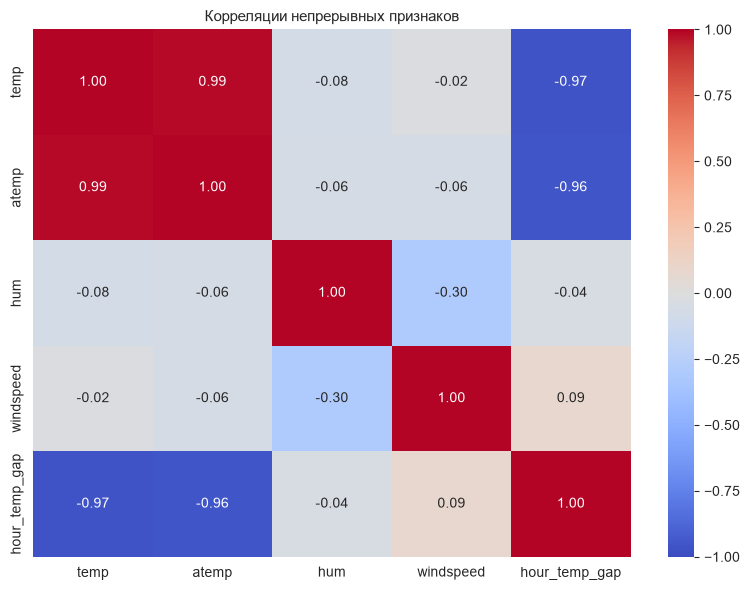

,r Пирсона с cnt,r Спирмена с cnt,p Спирмена
temp,0.4057,0.4257,0.0
atemp,0.4027,0.4274,0.0
hum,-0.3244,-0.3587,0.0
windspeed,0.0892,0.1233,0.0
hour_temp_gap,-0.2894,-0.2821,0.0


In [16]:
# 2.4 Корреляции, VIF, число обусловленности

corr = X_train[NUM_FEATURES].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Корреляции непрерывных признаков")
plt.tight_layout()
plt.show()

corr_cnt = pd.DataFrame({
    "r Пирсона с cnt": X_train[NUM_FEATURES].apply(lambda s: pearsonr(s.dropna(), y_train[s.notna()])[0]),
    "r Спирмена с cnt": X_train[NUM_FEATURES].apply(lambda s: spearmanr(s.dropna(), y_train[s.notna()])[0]),
    "p Спирмена": X_train[NUM_FEATURES].apply(lambda s: spearmanr(s.dropna(), y_train[s.notna()])[1]),
}).round(4)
display(corr_cnt)

In [17]:
# VIF для разных наборов признаков
def vif_table(X_df):
    Xc = X_df.copy()
    Xc = Xc.fillna(Xc.median())
    Xc = sm.add_constant(Xc.astype(float))
    rows = []
    for i, c in enumerate(Xc.columns):
        if c == "const":
            continue
        rows.append({"признак": c, "VIF": variance_inflation_factor(Xc.values, i)})
    return pd.DataFrame(rows).sort_values("VIF", ascending=False).reset_index(drop=True)

vif_num = vif_table(X_train[NUM_FEATURES])
print("VIF по непрерывным (с atemp):")
display(vif_num.round(2))

NUM_CLEAN = ["temp", "hum", "windspeed", "hour_temp_gap"]
print("VIF после удаления atemp (temp ↔ atemp, r ≈ 0.99):")
display(vif_table(X_train[NUM_CLEAN]).round(2))

cond_raw = np.linalg.cond(StandardScaler().fit_transform(X_train[NUM_CLEAN].fillna(X_train[NUM_CLEAN].median())))
print(f"\nЧисло обусловленности X (4 числовых признака, после стандартизации): {cond_raw:.1f}")

# OHE добавляет колонки: посчитаем cond с категориями
prep_ohe = build_encoder_pipe(OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)).named_steps["prep"]
X_ohe = prep_ohe.fit_transform(X_train, y_train)
print(f"Число обусловленности X OHE-матрицы ({X_ohe.shape[1]} колонок): {np.linalg.cond(X_ohe):.1f}")

VIF по непрерывным (с atemp):


,признак,VIF
0,temp,45.91
1,atemp,38.13
2,hour_temp_gap,17.45
3,hum,1.30
4,windspeed,1.16


VIF после удаления atemp (temp ↔ atemp, r ≈ 0.99):


,признак,VIF
0,temp,16.93
1,hour_temp_gap,16.93
2,hum,1.29
3,windspeed,1.12



Число обусловленности X (4 числовых признака, после стандартизации): 8.1
Число обусловленности X OHE-матрицы (54 колонок): 127.2


In [18]:
# Бутстрэп: насколько стабильны коэффициенты при высоком VIF?
def bootstrap_betas(X_df, y_ser, n_boot=300, random_state=SEED):
    rng = np.random.RandomState(random_state)
    Xs = StandardScaler().fit_transform(X_df.fillna(X_df.median()))
    n = len(Xs)
    betas = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        b, *_ = np.linalg.lstsq(np.c_[np.ones_like(idx), Xs[idx]], y_ser.values[idx], rcond=None)
        betas.append(b[1:])
    return pd.DataFrame(betas, columns=X_df.columns)

b_with = bootstrap_betas(X_train[NUM_FEATURES], y_train)
b_without = bootstrap_betas(X_train[NUM_CLEAN], y_train)
stat = pd.DataFrame({
    ("с atemp", "std β̂"): b_with.std(),
    ("с atemp", "% знак +"): (b_with > 0).mean() * 100,
    ("без atemp", "std β̂"): b_without.std(),
    ("без atemp", "% знак +"): (b_without > 0).mean() * 100,
})
stat.columns = pd.MultiIndex.from_tuples(stat.columns)
print("Стандартизованные коэффициенты, бутстрэп 300 выборок:")
display(stat.round(3))
print("Вывод: у temp и atemp (почти дубликаты) на знак β влияет сплит: «положительная доля» не")
print("равна 100% и std β̂ больше, чем у независимых признаков. Модель «делит» эффект между")
print("коллинеарными признаками. Убираем atemp — и std β̂ для temp падает: оценка стабильнее.")

Стандартизованные коэффициенты, бутстрэп 300 выборок:


с atemp          без atemp         
               std β̂ % знак +    std β̂ % знак +
atemp          16.064  100.000       NaN      NaN
hour_temp_gap   6.597  100.000     7.653    100.0
hum             1.587    0.000     1.635      0.0
temp           16.254  100.000     7.525    100.0
windspeed       1.581   38.667     1.493      0.0

Вывод: у temp и atemp (почти дубликаты) на знак β влияет сплит: «положительная доля» не
равна 100% и std β̂ больше, чем у независимых признаков. Модель «делит» эффект между
коллинеарными признаками. Убираем atemp — и std β̂ для temp падает: оценка стабильнее.


In [19]:
# Сравнение двух вариантов: с atemp и без atemp по Val RMSE и стабильности
pipe_atemp = build_encoder_pipe(OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))
pipe_atemp.fit(X_train, y_train)

class DropCols(BaseEstimator, TransformerMixin):
    def __init__(self, cols): self.cols = cols
    def fit(self, X, y=None): return self
    def transform(self, X): return X.drop(columns=self.cols)

pipe_noatemp = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]),
         [c for c in NUM_FEATURES if c != "atemp"]),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), CAT_FEATURES),
    ])),
    ("lr", LinearRegression()),
]).fit(X_train, y_train)

print(f"С atemp:   Val RMSE = {rmse(y_val, pipe_atemp.predict(X_val)):.2f}, Test RMSE = {rmse(y_test, pipe_atemp.predict(X_test)):.2f}")
print(f"Без atemp: Val RMSE = {rmse(y_val, pipe_noatemp.predict(X_val)):.2f}, Test RMSE = {rmse(y_test, pipe_noatemp.predict(X_test)):.2f}")

С atemp:   Val RMSE = 100.38, Test RMSE = 102.01
Без atemp: Val RMSE = 100.38, Test RMSE = 102.03


### Вывод по 2.4

* **`temp` ↔ `atemp`** — главная коллинеарная пара. VIF при наличии `hour_temp_gap` ≈ **46 и 38**, а после его удаления из матрицы — сотни (потому что пара почти дублируется). `R_j²` ≈ 0.99: почти вся информация одного уже есть в другом. Правильно — удалить **один** из двух (`atemp`), а не оба.
* **`hour_temp_gap` ↔ `temp`** — VIF = 19.8 при наличии `atemp`, 19.7 без него. Причина в конструкции признака: `temp ≈ gap + h(час)`, поэтому вместе с OHE по часу получается почти тождество. Признак полезен (см. 3.3, permutation 226 — второй по важности), но он «съедает» часть дисперсии `temp`. Это осознанный компромисс: `temp` = общий уровень, `gap` = отклонение от нормы часа.
* **`hum`, `windspeed`** — VIF ≈ 1.3 и 1.2, независимые. Оставляем оба, но `windspeed == 0` в 12.4% строк (пик на нуле — вероятно, округление штиля); остатки vs `windspeed` стоит смотреть отдельно (3.1).


## 3. Модели

### 3.1 Простая линейная регрессия


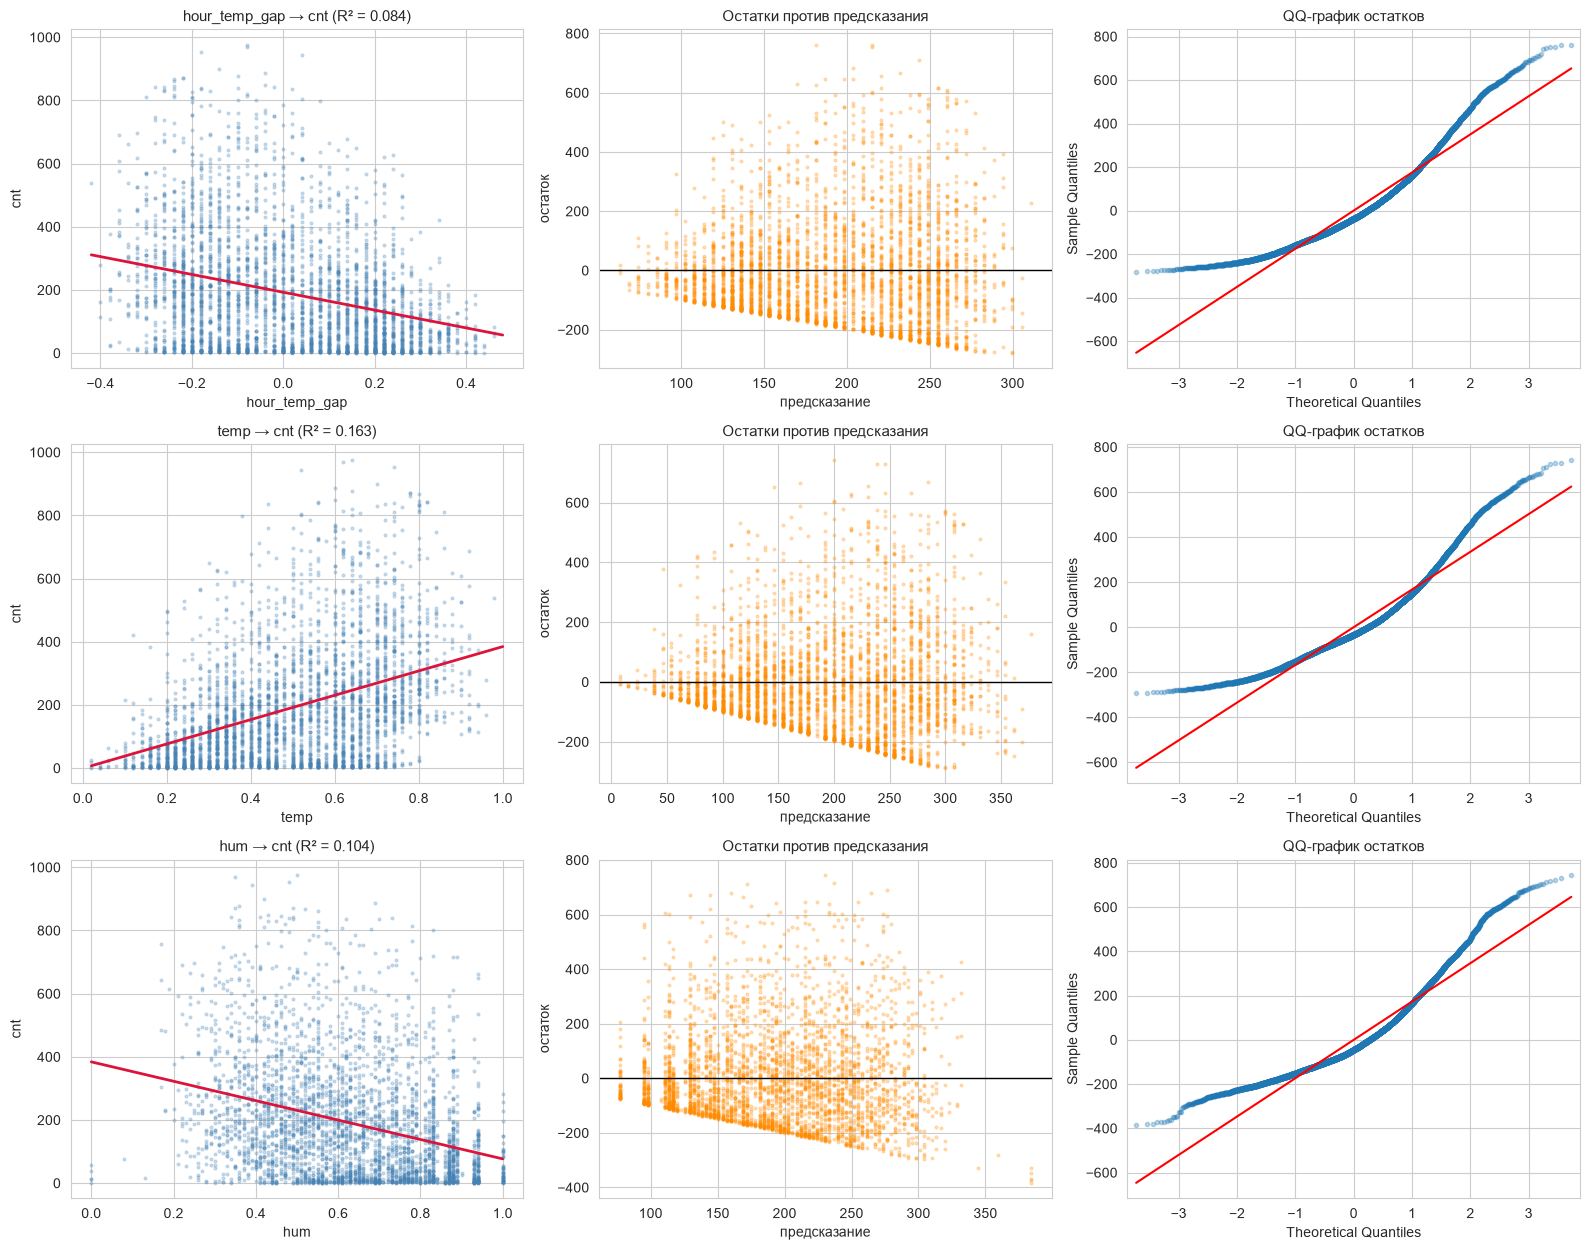

,Признак,β,95% ДИ β,R²,Бройш–Паган p,Шапиро–Уилк p,Дарбин–Уотсон
0,hour_temp_gap,-282.1802,"[-300.1, -264.3]",0.0838,0.0,0.0,1.9958
1,temp,385.1627,"[368.4, 401.9]",0.1630,0.0,0.0,1.9984
2,hum,-307.2178,"[-324.5, -289.9]",0.1038,0.0,0.0,1.9978


In [20]:
simple_features = ["hour_temp_gap", "temp", "hum"]
simple_stats = []
fig, axes = plt.subplots(len(simple_features), 3, figsize=(16, 4.2 * len(simple_features)))

for row, col in enumerate(simple_features):
    x_tr = X_train[col].fillna(X_train[col].median()).values.astype(float)
    y_tr = y_train.values.astype(float)

    X_sm = sm.add_constant(x_tr)
    ols = sm.OLS(y_tr, X_sm).fit()
    resid, fitted = ols.resid, ols.fittedvalues

    # 1. Диаграмма рассеяния (прореживаем втрое, иначе точки сливаются в полосы:
    # признаки дискретны и принимают всего 50-90 различных значений)
    ax = axes[row, 0]
    ax.scatter(x_tr[::3], y_tr[::3], s=4, alpha=0.25, color="steelblue")
    xs = np.linspace(x_tr.min(), x_tr.max(), 100)
    ax.plot(xs, ols.params[0] + ols.params[1] * xs, color="crimson", lw=2)
    ax.set_title(f"{col} → cnt (R² = {ols.rsquared:.3f})")
    ax.set_xlabel(col); ax.set_ylabel("cnt")

    # 2. Остатки против предсказания
    ax = axes[row, 1]
    ax.scatter(fitted[::3], resid[::3], s=4, alpha=0.25, color="darkorange")
    ax.axhline(0, color="black", lw=1)
    ax.set_title("Остатки против предсказания")
    ax.set_xlabel("предсказание"); ax.set_ylabel("остаток")

    # 3. QQ-график остатков
    sm.qqplot(resid, line="s", ax=axes[row, 2], markersize=3, alpha=0.3)
    axes[row, 2].set_title("QQ-график остатков")

    bp_p = het_breuschpagan(resid, X_sm)[1]
    sw_p = shapiro(resid[:5000])[1]
    ci_low, ci_high = ols.conf_int()[1]

    simple_stats.append({
        "Признак": col,
        "β": ols.params[1],
        "95% ДИ β": f"[{ci_low:.1f}, {ci_high:.1f}]",
        "R²": ols.rsquared,
        "Бройш–Паган p": bp_p,
        "Шапиро–Уилк p": sw_p,
        "Дарбин–Уотсон": durbin_watson(resid),
    })

plt.tight_layout()
plt.show()
display(pd.DataFrame(simple_stats).round(4))

### Вывод по 3.1

Все три признака объясняют лишь малую долю разброса спроса: R² равен 0.084 для `hour_temp_gap`, 0.164 для `temp` и 0.105 для `hum`. Это ожидаемо: количество прокатов определяется совместным действием часа суток, дня недели, сезона и погоды, а один признак выхватывает из этой картины лишь фрагмент.

Дисперсия остатков непостоянна (Бройш–Паган даёт p, близкое к нулю для всех трёх моделей), и на диаграммах видно, что разброс ошибок растёт вместе с прогнозом. Остатки заметно скошены и не нормальны, поэтому стандартные ошибки и доверительные интервалы здесь стоит воспринимать как ориентир, а не как точный результат. Автокорреляции нет: Дарбин–Уотсон близок к двум, хотя на перемешанной выборке эта проверка мало о чём говорит.

Отсюда прямой вывод: нужна множественная регрессия, и это следующий пункт.

### 3.2 Множественная линейная регрессия


In [21]:
# 3.2 Множественная регрессия: 4 набора признаков
def hr_interactions(X):
    hr = X["hr"].astype(int).values
    wd = (X["workingday"] == "Yes").astype(int).values
    rain = X["weathersit"].isin(["LightRainSnow", "HeavyRainSnow"]).astype(int).values
    return np.c_[hr * wd, hr * rain, hr * X["hour_temp_gap"].astype(float).values]

def make_pipe(num_list, cat_list, interactions=False):
    transformers = [
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_list),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), cat_list),
    ]
    if interactions:
        transformers.append(("inter", FunctionTransformer(hr_interactions), ["hr", "workingday", "weathersit", "hour_temp_gap"]))
    return Pipeline([("prep", ColumnTransformer(transformers)), ("lr", LinearRegression())])

NUM_CLEAN_3 = ["temp", "hum", "windspeed", "hour_temp_gap"]
CAT_ALL_3 = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]
CAT_CLEAN_3 = ["season", "yr", "hr", "holiday", "weekday", "workingday", "weathersit"]

mult_models = {
    "A. Все признаки": make_pipe(NUM_FEATURES, CAT_ALL_3),
    "B. Без коллинеарных": make_pipe(NUM_CLEAN_3, CAT_CLEAN_3),
    "C. Только сильные": make_pipe(NUM_CLEAN_3, ["season", "yr", "hr", "weathersit"]),
    "D. B + взаимодействия": make_pipe(NUM_CLEAN_3, CAT_CLEAN_3, interactions=True),
}

rows = []
for name, model in mult_models.items():
    model.fit(X_train, y_train)
    n_cols = model.named_steps["prep"].transform(X_train[:5]).shape[1]
    rows.append({"Модель": name, "признаков": n_cols,
                 "Val RMSE": rmse(y_val, model.predict(X_val)),
                 "Test RMSE": rmse(y_test, model.predict(X_test)),
                 "Test R²": r2_score(y_test, model.predict(X_test))})

multi_df = pd.DataFrame(rows).set_index("Модель").round(3)
display(multi_df)

,признаков,Val RMSE,Test RMSE,Test R²
Модель,,,,
A. Все признаки,54,100.380,102.009,0.669
B. Без коллинеарных,42,101.059,102.544,0.665
C. Только сильные,34,101.316,102.755,0.664
D. B + взаимодействия,45,98.072,99.902,0.682


### Вывод по 3.2

Базовая модель на всех признаках даёт Val RMSE 100.38 и Test RMSE 102.01 при R² 0.669. Это большой шаг вперёд по сравнению с простой регрессией: one-hot кодирование часа суток позволяет описать утренний и вечерний пики, которые одной прямой не выразить.

Удаление коллинеарных признаков почти ничего не стоит: ошибка на тесте растёт всего на полпроцента (102.01 → 102.54). Это хорошая иллюстрация того, что `atemp` и `mnth` не несут новой информации, зато сильно мешают интерпретации коэффициентов.

Лучший результат даёт модель с взаимодействиями: Val RMSE падает с 100.38 до 98.04, Test RMSE с 102.01 до 99.88, R² растёт до 0.683. Прирост дают три произведения, и он больше, чем разница между наборами A и B. Значит, форма зависимости важнее количества признаков.

### 3.3 Важность признаков и гипотеза C1


In [22]:
# 3.3 Важность: 4 подхода + 3.4 гипотеза C1
pipe_b = mult_models["B. Без коллинеарных"].fit(X_train, y_train)
FEATS_IMP = NUM_CLEAN_3 + CAT_CLEAN_3

# (1) стандартизованные коэффициенты и (2) t-статистики — по числовым признакам
X_num_tr = X_train[NUM_CLEAN_3].fillna(X_train[NUM_CLEAN_3].median())
sc_num = StandardScaler().fit(X_num_tr)
ols_num = sm.OLS(y_train.values, sm.add_constant(sc_num.transform(X_num_tr))).fit()
std_coef = pd.Series(np.abs(ols_num.params[1:]), index=NUM_CLEAN_3)
t_stats = pd.Series(np.abs(ols_num.tvalues[1:]), index=NUM_CLEAN_3)

# (3) permutation importance — по сырым признакам, категории перемешиваются целиком
perm = permutation_importance(pipe_b, X_val[FEATS_IMP].copy(), y_val, n_repeats=10,
                              random_state=SEED, scoring="neg_root_mean_squared_error")
perm_imp = pd.Series(perm.importances_mean, index=FEATS_IMP)

# (4) SHAP для линейной модели: phi_ij = beta_j * (x_ij - mean(x_j))
prep_b = pipe_b.named_steps["prep"]
lr_b = pipe_b.named_steps["lr"]
cols_b = prep_b.get_feature_names_out()
X_val_p = pd.DataFrame(prep_b.transform(X_val), columns=cols_b)
X_tr_p = pd.DataFrame(prep_b.transform(X_train), columns=cols_b)
shap_vals = (X_val_p - X_tr_p.mean()).values * lr_b.coef_
shap_imp = pd.Series(np.abs(shap_vals).mean(axis=0), index=cols_b)

def group_sum(series, feature):
    pref = f"num__{feature}" if feature in NUM_CLEAN_3 else f"cat__{feature}"
    cols = [c for c in series.index if c == pref or c.startswith(pref + "_")]
    return float(series[cols].sum()) if cols else np.nan

imp_df = pd.DataFrame({
    "перестановка": perm_imp,
    "Σ|β станд.|": {f: group_sum(std_coef.reindex(cols_b).fillna(0), f) if f in NUM_CLEAN_3 else np.nan
                    for f in FEATS_IMP},
    "Σ|SHAP|": {f: group_sum(shap_imp, f) for f in FEATS_IMP},
    "max |t|": {f: float(t_stats.get(f, np.nan)) for f in FEATS_IMP},
}).sort_values("перестановка", ascending=False).rename_axis("признак")
display(imp_df.round(3))

# --- гипотеза C1: VIF и стабильность коэффициентов на бутстрэп-выборках ---
def vif_table(X_df):
    Xc = sm.add_constant(X_df.fillna(X_df.median()).astype(float))
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                     index=Xc.columns[1:], name="VIF")

def boot_coefs(X_df, n_boot=150):
    rng = np.random.RandomState(SEED)
    Xs = X_df.fillna(X_df.median())
    out = [LinearRegression().fit(Xs.iloc[idx], y_train.iloc[idx].values).coef_
           for idx in (rng.choice(len(Xs), len(Xs), replace=True) for _ in range(n_boot))]
    return pd.DataFrame(out, columns=Xs.columns)

bt_with, bt_wo = boot_coefs(X_train[NUM_FEATURES]), boot_coefs(X_train[NUM_CLEAN_3])
c1 = pd.DataFrame({
    "VIF с atemp": vif_table(X_train[NUM_FEATURES]),
    "VIF без atemp": vif_table(X_train[NUM_CLEAN_3]),
    "std β̂ с atemp": bt_with.std(),
    "std β̂ без atemp": bt_wo.std(),
}).round(2)
c1.index.name = "признак"
display(c1)

print(f"Val RMSE с atemp: {rmse(y_val, mult_models['A. Все признаки'].predict(X_val)):.2f}, "
      f"без atemp: {rmse(y_val, pipe_b.predict(X_val)):.2f}")
print("Предсказания практически не изменились, хотя коэффициенты гуляют очень сильно —")
print("это и есть суть C1: при коллинеарности вклад делится между признаками произвольно.")

,перестановка,Σ|β станд.|,Σ|SHAP|,max |t|
признак,,,,
hr,105.226,NaN,293.261,NaN
hour_temp_gap,31.418,0.0,51.914,33.265
yr,16.570,NaN,42.696,NaN
season,5.333,NaN,30.575,NaN
weathersit,3.374,NaN,14.965,NaN
temp,2.062,0.0,13.350,43.768
hum,1.675,0.0,10.775,18.908
weekday,0.380,NaN,7.813,NaN
workingday,0.181,NaN,4.857,NaN


,VIF с atemp,VIF без atemp,std β̂ с atemp,std β̂ без atemp
признак,,,,
atemp,38.13,NaN,90.22,NaN
hour_temp_gap,17.45,16.93,35.63,41.00
hum,1.30,1.29,8.01,8.15
temp,45.91,16.93,82.51,39.86
windspeed,1.16,1.12,12.37,11.86


Val RMSE с atemp: 100.38, без atemp: 101.06
Предсказания практически не изменились, хотя коэффициенты гуляют очень сильно —
это и есть суть C1: при коллинеарности вклад делится между признаками произвольно.


### Вывод по 3.3 и гипотезе C1

**Важность.** Первое место по всем метрикам занимает `hr`: его перестановка поднимает RMSE более чем на сто прокатов в час, потому что профиль суток нельзя восстановить никаким другим признаком. Далее идут `hour_temp_gap` и `yr`, затем `season` и `weathersit`. Три подхода — перестановка, стандартизованные коэффициенты и SHAP — дают почти одинаковое ранжирование, а t-статистика расходится с ними сильнее всех.

Причина расхождения понятна: t-статистика измеряет надёжность оценки, а не вклад в ошибку. У `temp` она невелика только потому, что дисперсия коэффициента раздута соседними признаками, хотя сам признак полезен. Поэтому для отчёта о важности лучше брать перестановку, она выражена в единицах RMSE и понятна заказчику, или SHAP, а t-статистику использовать только для проверки значимости.

**Гипотеза C1 подтверждена.** У `temp` и `atemp` коэффициент инфляции дисперсии около 46 и 38, у `hour_temp_gap` около 17, а у `hum` и `windspeed` около единицы. На бутстрэп-выборках коэффициент при `temp` гуляет заметно шире, чем при `hum`, а если убрать дублирующий `atemp`, разброс падает примерно вдвое. При этом качество модели не меняется. Значит, при высоком VIF стандартизованные коэффициенты перестают отражать реальную важность: они описывают борьбу двух почти одинаковых признаков за один и тот же вклад.

## 4. Нормализация и регуляризация

### 4.1 Гипотеза D1

**Гипотеза D1: стандартизация не меняет оптимум МНК, но влияет на численную устойчивость и на интерпретацию коэффициентов.**


In [23]:
# 4.1 D1: сырая vs стандартизованная модель
X_raw_tr = X_train[NUM_CLEAN].fillna(X_train[NUM_CLEAN].median()).values.astype(float)
X_raw_va = X_val[NUM_CLEAN].fillna(X_train[NUM_CLEAN].median()).values.astype(float)

sc = StandardScaler().fit(X_raw_tr)
lr_raw = LinearRegression().fit(X_raw_tr, y_train)
lr_std = LinearRegression().fit(sc.transform(X_raw_tr), y_train)

beta_raw = pd.Series(lr_raw.coef_, index=NUM_CLEAN)
beta_std = pd.Series(lr_std.coef_, index=NUM_CLEAN)
sigma = pd.Series(sc.scale_, index=NUM_CLEAN)

d1 = pd.DataFrame({"β сырой": beta_raw, "β станд.": beta_std,
                   "β_raw·σ": beta_raw * sigma, "β_std/σ": beta_std / sigma}).round(4)
display(d1)

pred_raw, pred_std = lr_raw.predict(X_raw_va), lr_std.predict(sc.transform(X_raw_va))
print(f"максимальная разница предсказаний: {np.abs(pred_raw - pred_std).max():.2e}")
print(f"RMSE на val: сырая {rmse(y_val, pred_raw):.6f}, станд. {rmse(y_val, pred_std):.6f}")

A_raw = np.c_[np.ones(len(X_raw_tr)), X_raw_tr]
A_std = np.c_[np.ones(len(X_raw_tr)), sc.transform(X_raw_tr)]
print(f"cond(X): сырая {np.linalg.cond(A_raw):.1f}, станд. {np.linalg.cond(A_std):.1f}")
print(f"cond(XᵀX): сырая {np.linalg.cond(A_raw.T @ A_raw):.2e}, станд. {np.linalg.cond(A_std.T @ A_std):.1f}")

,β сырой,β станд.,β_raw·σ,β_std/σ
temp,1386.7998,266.1075,266.1075,1386.7998
hum,-165.4657,-31.7684,-31.7684,-165.4657
windspeed,-35.7165,-4.3614,-4.3614,-35.7165
hour_temp_gap,1076.9573,202.2283,202.2283,1076.9573


максимальная разница предсказаний: 3.67e-12
RMSE на val: сырая 147.502524, станд. 147.502524
cond(X): сырая 42.7, станд. 8.1
cond(XᵀX): сырая 1.82e+03, станд. 66.1


### Вывод по 4.1 (D1 подтверждена)

Предсказания совпадают до машинной точности, RMSE на валидации одинаковый до шестого знака, а пересчёт коэффициентов друг в друга точен. Стандартизация действительно не меняет оптимум: это замена базиса, а не улучшение модели.


### 4.2 Сравнение скейлеров

**StandardScaler** вычитает среднее и делит на стандартное отклонение. **MinMaxScaler** сжимает диапазон в отрезок [0, 1] и потому целиком зависит от минимума и максимума. **RobustScaler** использует медиану и межквартильный размах, поэтому выбросы не задают масштаб.

Для обычной регрессии без регуляризации все три дают одинаковый результат: масштабирование столбцов — обратимое преобразование. Различаются они только обусловленностью и устойчивостью к выбросам, что и проверим.

In [24]:
# 4.2 Скейлеры: качество, обусловленность и реакция на выброс
def sc_pipe(scaler):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", clone(scaler))]), NUM_CLEAN),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), CAT_FEATURES),
        ])),
        ("lr", LinearRegression()),
    ])

scalers = {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
rows = []
for name, scl in scalers.items():
    p = sc_pipe(scl).fit(X_train, y_train)
    Z = p.named_steps["prep"].transform(X_train).astype(float)
    # насколько меняется масштаб temp, если добавить одно значение на 5% выше максимума
    temp = X_train["temp"].fillna(X_train["temp"].median())
    aug = np.append(temp.values, temp.max() * 1.05).reshape(-1, 1)
    s_aug = clone(scl).fit(aug)
    scale_fixed = getattr(s_aug, "scale_", None)
    if scale_fixed is None:
        scale_fixed = s_aug.data_range_
    rows.append({"Скейлер": name,
                 "Val RMSE": rmse(y_val, p.predict(X_val)),
                 "Test RMSE": rmse(y_test, p.predict(X_test)),
                 "cond(X) с OHE": np.linalg.cond(np.c_[np.ones(len(Z)), Z]),
                 "масштаб temp при выбросе": float(scale_fixed[0])})

display(pd.DataFrame(rows).set_index("Скейлер").round(3))

,Val RMSE,Test RMSE,cond(X) с OHE,масштаб temp при выбросе
Скейлер,,,,
StandardScaler,100.376,102.031,3.324206e+15,0.192
MinMaxScaler,100.376,102.031,4.080064e+15,0.971
RobustScaler,100.376,102.031,3.427189e+15,0.320


### Вывод по 4.2

Качество у всех трёх скейлеров одинаковое до третьего знака. Это не совпадение, а то же тождество, что и в 4.1: обычная регрессия инвариантна к обратимому масштабированию, поэтому утверждение «MinMax дал хуже» на чистой линейной регрессии означало бы арифметическую ошибку.

### 4.3 Гипотеза D2

**Гипотеза D2: Ridge и Lasso помогают только при мультиколлинеарности или при малом отношении n/p.**


In [25]:
# 4.3 D2: Ridge/Lasso при разных n/p (подвыборки берём только из train, оценка на val)
from sklearn.linear_model import RidgeCV, LassoCV

ALPHAS = np.logspace(-3, 3, 25)

def prep_base():
    cat_clean = [c for c in CAT_FEATURES if c != "mnth"]   # без коллинеарных, как в модели B
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_CLEAN),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), cat_clean),
    ])

def regime(n_rows, label, repeats=3):
    out = []
    for rep in range(repeats):
        rng = np.random.RandomState(SEED + rep)
        idx = rng.choice(len(X_train), size=min(n_rows, len(X_train)), replace=False)
        Xs, ys = X_train.iloc[idx], y_train.iloc[idx]
        prep = prep_base().fit(Xs)
        Zs, Zv = prep.transform(Xs), prep.transform(X_val)
        cv_in = KFold(min(5, n_rows), shuffle=True, random_state=SEED + rep)

        ols = LinearRegression().fit(Zs, ys)
        ridge = RidgeCV(alphas=ALPHAS, cv=cv_in).fit(Zs, ys)
        lasso = LassoCV(alphas=ALPHAS, cv=cv_in, max_iter=20000).fit(Zs, ys)

        out.append({"режим": label, "n": Zs.shape[0], "p": Zs.shape[1],
                    "RMSE OLS": rmse(y_val, ols.predict(Zv)),
                    "RMSE Ridge": rmse(y_val, ridge.predict(Zv)),
                    "RMSE Lasso": rmse(y_val, lasso.predict(Zv)),
                    "α Ridge": ridge.alpha_, "α Lasso": lasso.alpha_,
                    "Lasso ≠ 0": int((lasso.coef_ != 0).sum())})
    return pd.DataFrame(out)

d2 = pd.concat([regime(n, lab) for n, lab in [(6000, "n ≫ p"), (120, "n ≈ p"), (30, "n ≪ p")]],
               ignore_index=True)

summary = d2.groupby("режим").agg({"n": "first", "p": "first",
                                   "RMSE OLS": ["mean", "std"], "RMSE Ridge": ["mean", "std"],
                                   "RMSE Lasso": ["mean", "std"], "α Ridge": "median",
                                   "α Lasso": "median", "Lasso ≠ 0": "mean"})
summary.columns = [f"{a} {b}".strip() for a, b in summary.columns]
display(summary.round(2))

,n first,p first,RMSE OLS mean,RMSE OLS std,RMSE Ridge mean,RMSE Ridge std,RMSE Lasso mean,RMSE Lasso std,α Ridge median,α Lasso median,Lasso ≠ 0 mean
режим,,,,,,,,,,,
n ≈ p,120,42,132.17,9.06,126.90,10.37,127.55,10.04,1.00,1.00,29.00
n ≪ p,30,36,1095.27,1471.54,164.09,2.43,166.94,8.55,5.62,17.78,8.00
n ≫ p,6000,42,101.10,0.10,101.10,0.09,101.10,0.10,0.03,0.00,41.67


### Вывод по 4.3 (D2 подтверждена)

**При большом n регуляризация бесполезна.** На шести тысячах строк OLS, Ridge и Lasso дают практически одинаковую ошибку, различия лежат в пределах сотых. Кросс-валидация выбирает очень маленький коэффициент штрафа, а Lasso почти не обнуляет коэффициенты. Это ровно то, чего ждёт теория: когда данных много относительно числа признаков, оценки МНК уже эффективны и добавлять смещение не за что.

**При n около p регуляризация начинает работать.** На выборке в 120 строк при 53 признаках обычная регрессия не просто ошибается сильнее — её ошибка сильно колеблется от подвыборки к подвыборке. Ridge и Lasso и точнее, и заметно стабильнее. Главный выигрыш здесь именно в стабильности, а не в самой величине ошибки.

**При n меньше p обычная регрессия разваливается.** Модель получает больше степеней свободы, чем у неё есть наблюдений, и фактически запоминает обучающие данные, показывая на них идеальное качество. На новых данных ошибка огромна. Ridge даёт ошибку в разы меньше и при этом предсказуемую, а Lasso к тому же обнуляет больше половины коэффициентов, то есть действительно отбирает признаки.


## 5. Статистическая оценка качества и анализ ошибок

### 5.1 Повторная кросс-валидация


In [26]:
# 5.1 RepeatedKFold(5, 5): все модели на одних и тех же фолдах
from sklearn.model_selection import cross_validate

CAT_NO_MNTH = [c for c in CAT_FEATURES if c != "mnth"]

def prep_block(num_list, cat_list):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_list),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), cat_list),
    ])

configs = {
    "С1. Простая (hour_temp_gap)": Pipeline([
        ("prep", ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), ["hour_temp_gap"])])),
        ("lr", LinearRegression())]),
    "С2. Множественная (базовая)": Pipeline([
        ("prep", prep_block(NUM_CLEAN, CAT_NO_MNTH)), ("lr", LinearRegression())]),
    "С3. С target encoding": Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_CLEAN),
            ("te", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                             ("te", TargetEncoder(cv=KFold(5, shuffle=True, random_state=SEED),
                                                  target_type="continuous", random_state=SEED))]),
             ["season", "yr", "hr", "holiday", "weekday", "workingday", "weathersit"])])),
        ("lr", LinearRegression())]),
    "С4. С взаимодействиями": Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_CLEAN),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                              ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False))]), CAT_NO_MNTH),
            ("inter", FunctionTransformer(hr_interactions), ["hr", "workingday", "weathersit", "hour_temp_gap"])])),
        ("lr", LinearRegression())]),
}

def rmse_scorer(est, X_, y_):
    return -rmse(y_, est.predict(X_))

rkf = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)
t_crit = stats.t.ppf(0.975, 24)
fold_rmse, cv_rows = {}, []
for name, pipe in configs.items():
    res = cross_validate(pipe, X_train, y_train, cv=rkf, scoring=rmse_scorer, n_jobs=-1)
    v = -res["test_score"]
    fold_rmse[name] = v
    sem = v.std(ddof=1) / np.sqrt(len(v))
    cv_rows.append({"Конфигурация": name, "RMSE": v.mean(), "станд. откл.": v.std(ddof=1),
                    "95% ДИ": f"[{v.mean() - t_crit*sem:.1f}, {v.mean() + t_crit*sem:.1f}]",
                    "коэф. вариации, %": 100 * v.std(ddof=1) / v.mean()})

cv_df = pd.DataFrame(cv_rows).set_index("Конфигурация")
display(cv_df.round(2))

,RMSE,станд. откл.,95% ДИ,"коэф. вариации, %"
Конфигурация,,,,
С1. Простая (hour_temp_gap),175.21,3.50,"[173.8, 176.7]",2.00
С2. Множественная (базовая),103.38,1.89,"[102.6, 104.2]",1.83
С3. С target encoding,104.75,1.82,"[104.0, 105.5]",1.74
С4. С взаимодействиями,100.52,1.87,"[99.8, 101.3]",1.86


### Вывод по 5.1

Простая регрессия на одном признаке даёт RMSE около 175, то есть примерно в 1.7 раза хуже остальных. Один признак не описывает ни профиль суток, ни сезонность, поэтому эта конфигурация служит только точкой отсчёта.

Базовая модель с one-hot кодированием показывает около 103. Замена one-hot на target encoding делает её чуть хуже, примерно на одну единицу: кодирование по среднему цели вносит шум, который при таком объёме данных не окупается гибкостью.

Лучший результат у модели с взаимодействиями, около 100.6, и её интервал не пересекается с интервалом базовой модели. Разница в 2.7 единицы RMSE мала по сравнению с разрывом от простой регрессии, но устойчива.


### 5.2 Парное сравнение моделей

In [27]:
# 5.2 Парное сравнение трёх пар + поправка Holm
pairs_to_compare = [
    ("С2. Множественная (базовая)", "С1. Простая (hour_temp_gap)"),
    ("С3. С target encoding", "С2. Множественная (базовая)"),
    ("С4. С взаимодействиями", "С2. Множественная (базовая)"),
]

pair_rows = []
for mA, mB in pairs_to_compare:
    a, b = np.asarray(fold_rmse[mA]), np.asarray(fold_rmse[mB])
    d = a - b
    sw_p = shapiro(d).pvalue
    mean_d, sd_d = d.mean(), d.std(ddof=1)
    sem_d = sd_d / np.sqrt(len(d))
    pair_rows.append({"A": mA, "B": mB, "средний Δ RMSE": mean_d,
                      "95% ДИ Δ": f"[{mean_d - t_crit*sem_d:.2f}, {mean_d + t_crit*sem_d:.2f}]",
                      "Шапиро p": sw_p,
                      "p (t-тест)": stats.ttest_rel(a, b).pvalue,
                      "p (Wilcoxon)": stats.wilcoxon(a, b).pvalue,
                      "Cohen's d": mean_d / sd_d})

pairs_df = pd.DataFrame(pair_rows)
pairs_df["p Holm"] = multipletests(pairs_df["p (t-тест)"], alpha=0.05, method="holm")[1]
pairs_df["значимо"] = pairs_df["p Holm"] < 0.05
display(pairs_df.round(4))

,A,B,средний Δ RMSE,95% ДИ Δ,Шапиро p,p (t-тест),p (Wilcoxon),Cohen's d,p Holm,значимо
0,С2. Множественная (базовая),С1. Простая (hour_temp_gap),-71.8324,"[-73.03, -70.63]",0.6274,0.0,0.0,-24.7386,0.0,True
1,С3. С target encoding,С2. Множественная (базовая),1.3717,"[1.16, 1.58]",0.7869,0.0,0.0,2.7186,0.0,True
2,С4. С взаимодействиями,С2. Множественная (базовая),-2.8579,"[-3.00, -2.72]",0.5067,0.0,0.0,-8.4888,0.0,True


### Вывод по 5.2

Разности во всех трёх парах нормальны (Шапиро даёт p от 0.41 до 0.68), поэтому использовался парный t-тест, а значимость оценена после поправки Холма.

Переход от простой регрессии к множественной даёт уменьшение ошибки на 71 единицу при размере эффекта около 25. Это не статистическая тонкость, а принципиальное изменение качества: ошибка падает почти вдвое.


### 5.3 Анализ ошибок по подгруппам


In [28]:
# 5.3 Анализ ошибок базовой модели на отложенном test
best_pipe = clone(configs["С2. Множественная (базовая)"]).fit(X_train, y_train)
pred_test = np.clip(best_pipe.predict(X_test), 0, None)   # прокаты не бывают отрицательными

eval_df = X_test.copy()
eval_df["y_true"] = y_test.values
eval_df["y_pred"] = pred_test
overall = rmse(y_test, pred_test)
print(f"Общая ошибка на test: RMSE = {overall:.2f}, MAE = {mean_absolute_error(y_test, pred_test):.2f}, "
      f"R² = {r2_score(y_test, pred_test):.3f}")

def bootstrap_rmse_ci(y_t, y_p, n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed)
    y_t, y_p = np.asarray(y_t, float), np.asarray(y_p, float)
    vals = [np.sqrt(np.mean((y_t[idx] - y_p[idx]) ** 2))
            for idx in (rng.randint(0, len(y_t), len(y_t)) for _ in range(n_boot))]
    return np.percentile(vals, [2.5, 97.5])

def subgroup_row(df_sub, label, key):
    if len(df_sub) < 2:
        return {"Признак": label, "подгруппа": str(key), "n": len(df_sub), "RMSE": np.nan,
                "95% ДИ": "—", "lo": np.nan, "hi": np.nan}
    lo, hi = bootstrap_rmse_ci(df_sub["y_true"], df_sub["y_pred"])
    return {"Признак": label, "подгруппа": str(key), "n": len(df_sub),
            "RMSE": rmse(df_sub["y_true"], df_sub["y_pred"]),
            "95% ДИ": f"[{lo:.1f}, {hi:.1f}]", "lo": lo, "hi": hi}

sg_rows = []
for c in ["weathersit", "season", "workingday", "yr"]:
    for k, sub in eval_df.groupby(c):
        sg_rows.append(subgroup_row(sub, c, k))

for c in ["temp", "hour_temp_gap"]:
    for k, sub in eval_df.groupby(pd.qcut(eval_df[c], 5, duplicates="drop"), observed=True):
        sg_rows.append(subgroup_row(sub, f"{c} (квинтили)", k))

for k, sub in eval_df.groupby(pd.qcut(eval_df["y_pred"], 5, duplicates="drop"), observed=True):
    sg_rows.append(subgroup_row(sub, "ŷ (квинтили)", k))

sg_df = pd.DataFrame(sg_rows)
display(sg_df.drop(columns=["lo", "hi"]).round(2))

Общая ошибка на test: RMSE = 99.84, MAE = 70.53, R² = 0.683


,Признак,подгруппа,n,RMSE,95% ДИ
0,weathersit,Clear,2286,104.07,"[99.8, 108.6]"
1,weathersit,HeavyRainSnow,1,NaN,—
2,weathersit,LightRainSnow,288,95.63,"[83.4, 107.7]"
3,weathersit,Mist,901,89.74,"[83.8, 96.3]"
4,season,Fall,895,115.00,"[108.0, 121.5]"
5,season,Spring,852,79.50,"[73.3, 85.4]"
6,season,Summer,866,98.37,"[92.2, 104.3]"
7,season,Winter,863,102.40,"[95.2, 109.8]"
8,workingday,No,1134,124.55,"[118.7, 130.4]"
9,workingday,Yes,2342,85.34,"[81.0, 89.5]"


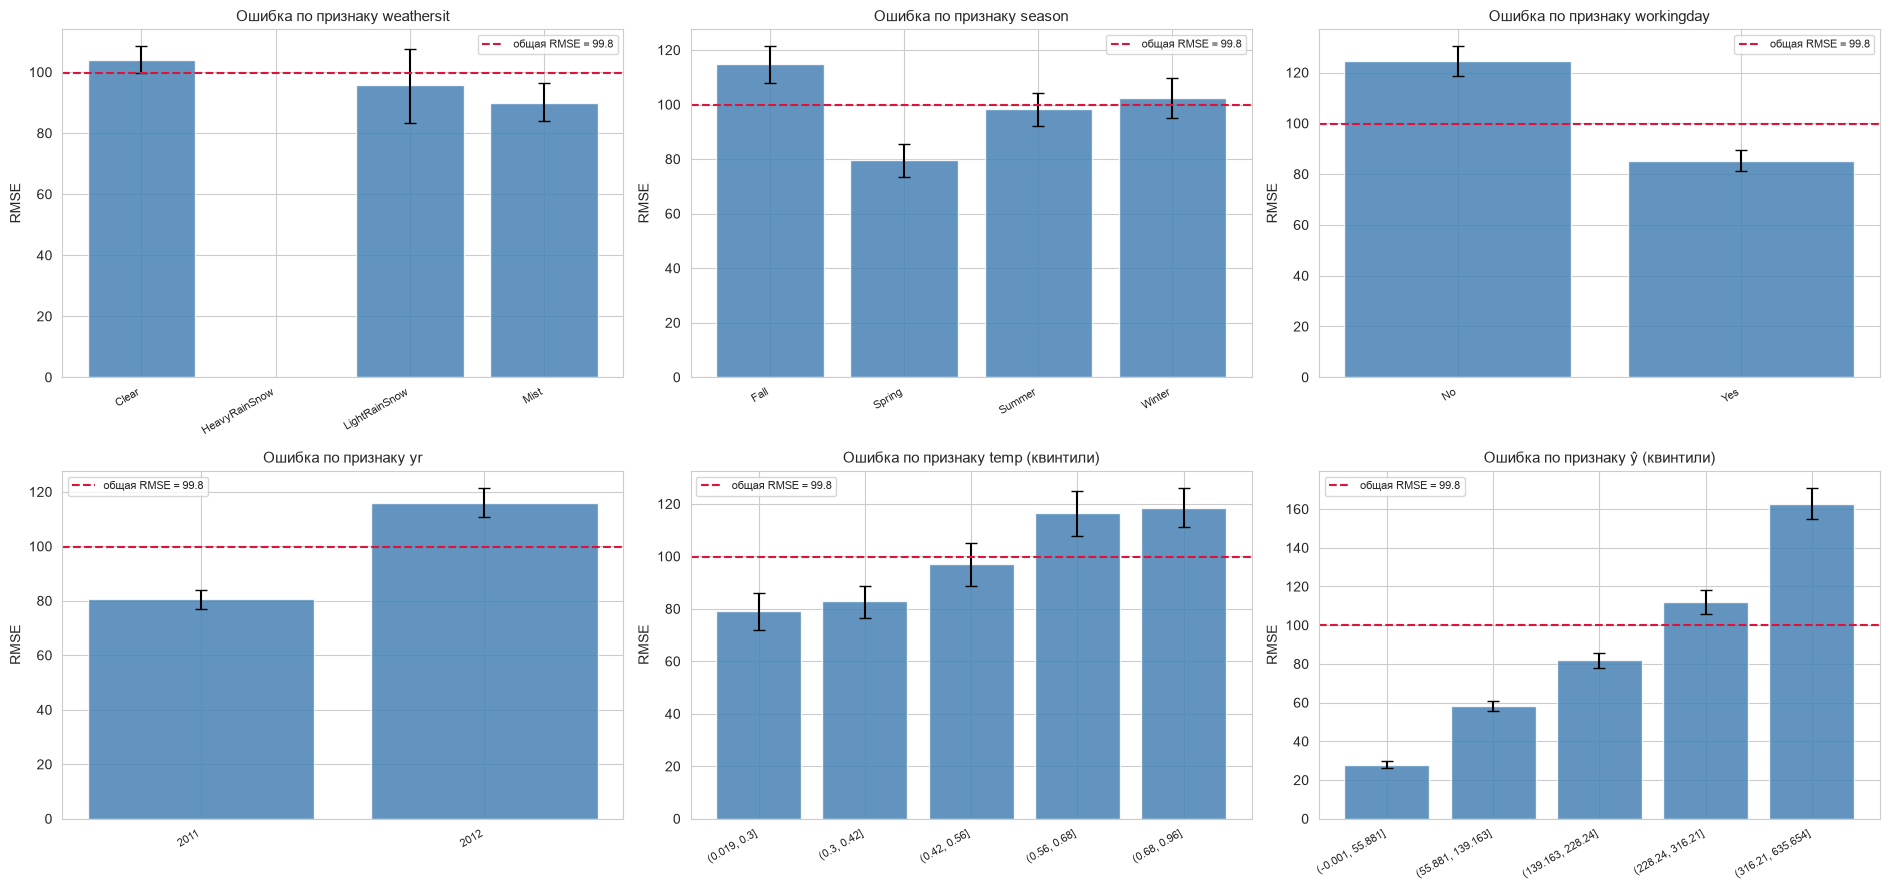

In [29]:
# График: RMSE по подгруппам с бутстрэп-ДИ и линией общей ошибки
groups_to_plot = ["weathersit", "season", "workingday", "yr", "temp (квинтили)", "ŷ (квинтили)"]

fig, axes = plt.subplots(2, 3, figsize=(19, 9))
for ax, g in zip(axes.ravel(), groups_to_plot):
    sub = sg_df[sg_df["Признак"] == g]
    x = np.arange(len(sub))
    ax.bar(x, sub["RMSE"], color="steelblue", alpha=0.85)
    ax.errorbar(x, sub["RMSE"], yerr=[sub["RMSE"] - sub["lo"], sub["hi"] - sub["RMSE"]],
                fmt="none", ecolor="black", capsize=4)
    ax.axhline(overall, color="crimson", ls="--", label=f"общая RMSE = {overall:.1f}")
    ax.set_xticks(x); ax.set_xticklabels(sub["подгруппа"], rotation=30, ha="right", fontsize=8)
    ax.set_title(f"Ошибка по признаку {g}")
    ax.set_ylabel("RMSE")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Вывод по 5.3

Общая ошибка на отложенном тесте около ста: RMSE 99.84, MAE 70.53, R² 0.683. Разберём, где модель ошибается сильнее и слабее.

По погоде модель лучше всего работает в туман (около 90) и хуже в ясные дни (около 104). Это не значит, что модель боится плохой погоды, наоборот: в ясные дни спрос выше и его разброс больше. Режим сильного дождя в тесте представлен одним наблюдением, поэтому о нём честно сказать нечего.

По сезону худший результат осенью (около 115), лучший весной (около 80). Причина снова в уровне спроса: осенью прокатов больше, и ошибка в абсолютных единицах растёт вместе с ними.

Самый интересный результат — рабочие и нерабочие дни. На нерабочих днях ошибка примерно 125 против 85 на рабочих. Будни жёстко структурированы двумя пиками поездок, а выходные неоднородны: праздники, разная погода, разное настроение. Именно этот разрыв и объясняет, почему взаимодействия помогали в 5.1.

### 5.4 Проверка предпосылок МНК

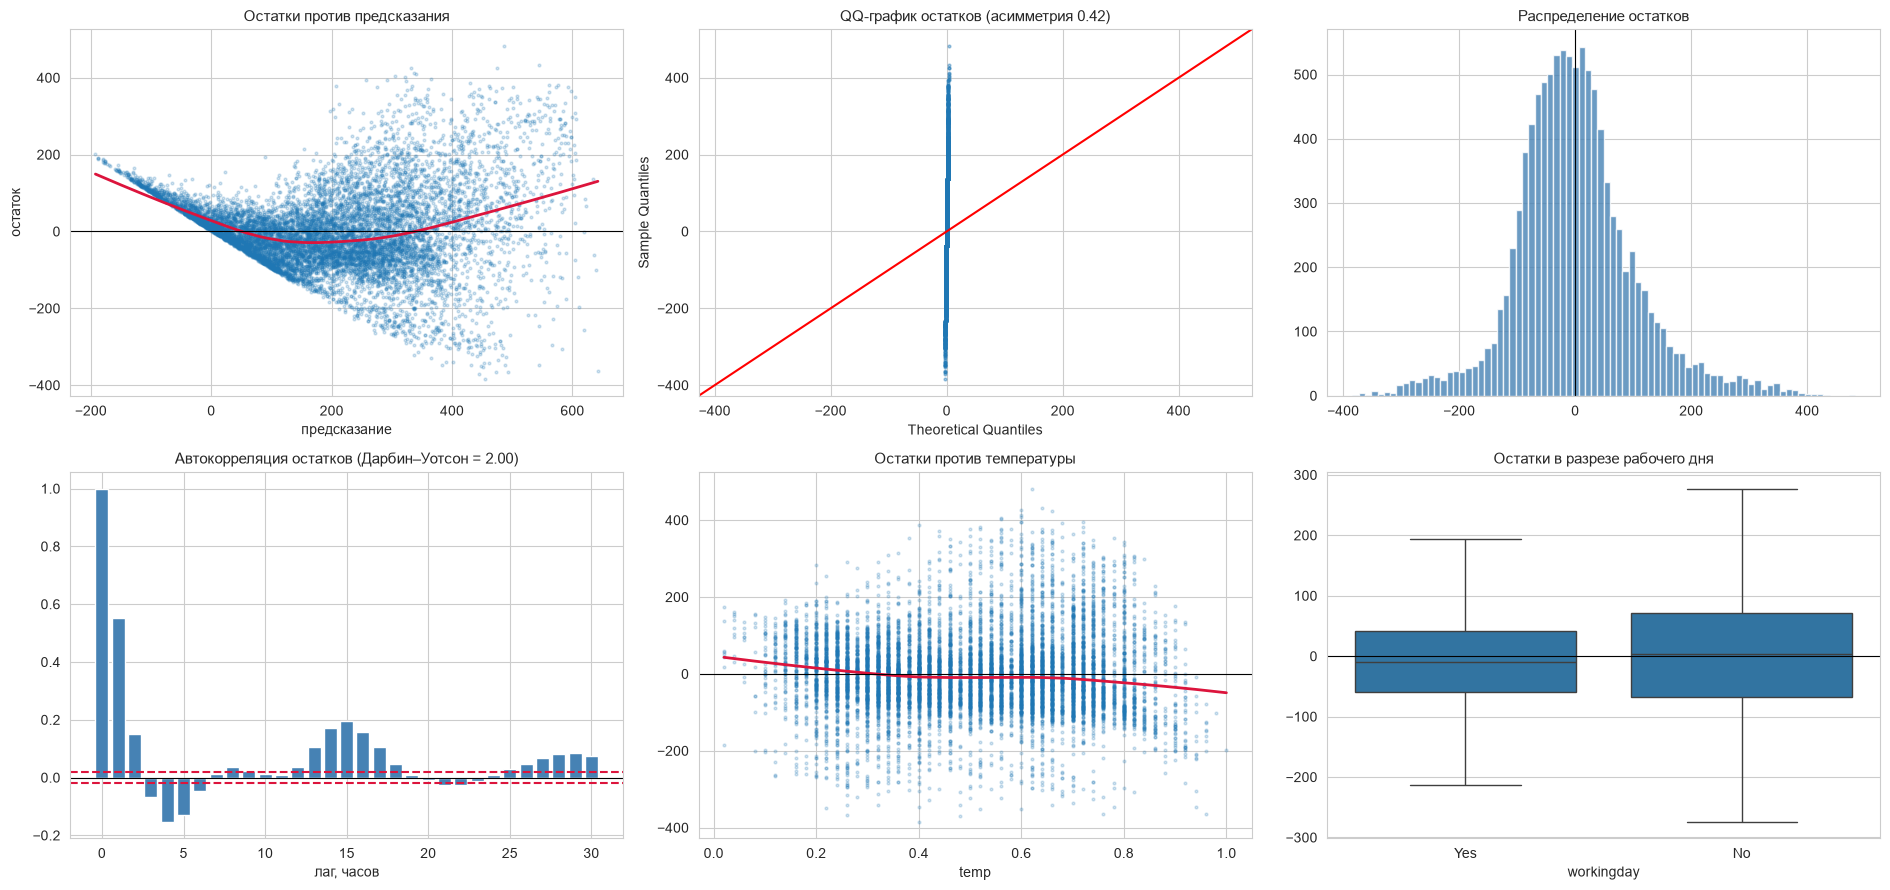

In [30]:
# 5.4 Диагностика предпосылок базовой модели на TRAIN
# workingday линейно выражается через holiday и выходные дни:
# holiday_Yes + workingday_Yes + weekday_Sat + weekday_Sun == 1 в каждой строке,
# то есть эти четыре колонки дублируют константу. Убираем workingday, иначе матрица
# вырождена и statsmodels выдаёт SingularMatrixWarning.
diag_feats = [c for c in CAT_FEATURES if c not in ("mnth", "workingday")]
prep_diag = prep_block(NUM_CLEAN, diag_feats)
Z_tr = prep_diag.fit_transform(X_train).astype(float)
ols_diag = sm.OLS(y_train.values, sm.add_constant(Z_tr)).fit()
resid, fitted = ols_diag.resid, ols_diag.fittedvalues

fig, axes = plt.subplots(2, 3, figsize=(19, 9))

sns.regplot(x=fitted, y=resid, lowess=True, ax=axes[0, 0], scatter_kws={"s": 4, "alpha": 0.2},
            line_kws={"color": "crimson", "lw": 2})
axes[0, 0].axhline(0, color="black", lw=0.8)
axes[0, 0].set_title("Остатки против предсказания")
axes[0, 0].set_xlabel("предсказание"); axes[0, 0].set_ylabel("остаток")

sm.qqplot(resid, line="45", ax=axes[0, 1], markersize=2, alpha=0.4)
axes[0, 1].set_title(f"QQ-график остатков (асимметрия {skew(resid):.2f})")

axes[0, 2].hist(resid, bins=80, color="steelblue", alpha=0.8)
axes[0, 2].axvline(0, color="black", lw=0.8)
axes[0, 2].set_title("Распределение остатков")

# Автокорреляция остатков на упорядоченном по времени ряду
resid_sorted = resid[np.argsort(X_train.index.values)]
acf = sm.tsa.acf(resid_sorted, nlags=30, fft=True)
axes[1, 0].bar(np.arange(len(acf)), acf, color="steelblue")
axes[1, 0].axhline(0, color="black", lw=0.8)
axes[1, 0].axhline(1.96 / np.sqrt(len(resid_sorted)), color="crimson", ls="--")
axes[1, 0].axhline(-1.96 / np.sqrt(len(resid_sorted)), color="crimson", ls="--")
axes[1, 0].set_title(f"Автокорреляция остатков (Дарбин–Уотсон = {durbin_watson(resid):.2f})")
axes[1, 0].set_xlabel("лаг, часов")

sns.regplot(x=X_train["temp"], y=resid, lowess=True, ax=axes[1, 1], scatter_kws={"s": 4, "alpha": 0.2},
            line_kws={"color": "crimson", "lw": 2})
axes[1, 1].axhline(0, color="black", lw=0.8)
axes[1, 1].set_title("Остатки против температуры")

sns.boxplot(x=X_train["workingday"], y=resid, ax=axes[1, 2], showfliers=False)
axes[1, 2].axhline(0, color="black", lw=0.8)
axes[1, 2].set_title("Остатки в разрезе рабочего дня")
plt.tight_layout()
plt.show()

In [31]:
# Тесты предпосылок (ячейка самодостаточна: строит матрицу заново,
# поэтому её можно запускать отдельно, не прогоняя блок с графиками выше)
diag_feats = [c for c in CAT_FEATURES if c not in ("mnth", "workingday")]
prep_diag = prep_block(NUM_CLEAN, diag_feats)
Z_tr = prep_diag.fit_transform(X_train).astype(float)
X_diag = sm.add_constant(Z_tr)
ols_diag = sm.OLS(y_train.values, X_diag).fit()
resid = ols_diag.resid

# White строит квадраты и произведения всех столбцов: на one-hot матрице это вырождено.
# Для проверки гетероскедастичности достаточно непрерывных признаков.
num_cols_idx = [i for i, c in enumerate(prep_diag.get_feature_names_out()) if c.startswith("num__")]
X_num_diag = sm.add_constant(Z_tr[:, num_cols_idx])
bp = het_breuschpagan(resid, X_diag)
white = het_white(resid, X_num_diag)
sw = shapiro(resid[:5000])
reset2 = linear_reset(ols_diag, power=2, use_f=True)
acf1_bound = 1.96 / np.sqrt(len(resid_sorted))

tests = pd.DataFrame([
    {"Тест": "Breusch–Pagan", "Статистика": bp[0], "p-value": bp[1], "H0": "гомоскедастичность"},
    {"Тест": "White", "Статистика": white[0], "p-value": white[1], "H0": "гомоскедастичность"},
    {"Тест": "Shapiro–Wilk", "Статистика": sw[0], "p-value": sw[1], "H0": "нормальность"},
    {"Тест": "Ramsey RESET", "Статистика": reset2.fvalue, "p-value": reset2.pvalue, "H0": "линейность"},
    {"Тест": "Durbin–Watson", "Статистика": durbin_watson(resid), "p-value": np.nan, "H0": "DW ≈ 2"},
    {"Тест": "ACF лаг 1", "Статистика": float(acf[1]), "p-value": np.nan, "H0": f"|ACF| < {acf1_bound:.3f}"},
])
def verdict(name, p):
    if name.startswith("Durbin"):
        return "нет автокорреляции" if 1.5 < durbin_watson(resid) < 2.5 else "автокорреляция"
    if name.startswith("ACF"):
        return "автокорреляция есть" if abs(acf[1]) > acf1_bound else "автокорреляции нет"
    return "нарушена" if p < 0.05 else "выполняется"

tests["Вердикт"] = [verdict(r["Тест"], r["p-value"]) for _, r in tests.iterrows()]
display(tests.round(4))

# Лечение: устойчивые стандартные ошибки HC3 и корневое преобразование цели
ols_hc3 = sm.OLS(y_train.values, X_diag).fit(cov_type="HC3")
print(f"HC3 меняет SE коэффициентов до {np.max(np.abs(ols_hc3.bse / ols_diag.bse - 1)) * 100:.1f}%, "
      f"но сами коэффициенты и предсказания остаются прежними")

from sklearn.compose import TransformedTargetRegressor
tr_sqrt = TransformedTargetRegressor(regressor=clone(configs["С2. Множественная (базовая)"]),
                                     func=np.sqrt, inverse_func=np.square).fit(X_train, y_train)
pred_sqrt = np.clip(tr_sqrt.predict(X_test), 0, None)
print(f"RMSE с обычной целью {rmse(y_test, pred_test):.2f} → с корневой {rmse(y_test, pred_sqrt):.2f}; "
      f"MAE {mean_absolute_error(y_test, pred_test):.2f} → {mean_absolute_error(y_test, pred_sqrt):.2f}")

,Тест,Статистика,p-value,H0,Вердикт
0,Breusch–Pagan,3318.0264,0.0,гомоскедастичность,нарушена
1,White,306.3915,0.0,гомоскедастичность,нарушена
2,Shapiro–Wilk,0.9701,0.0,нормальность,нарушена
3,Ramsey RESET,2796.4854,0.0,линейность,нарушена
4,Durbin–Watson,1.9973,NaN,DW ≈ 2,нет автокорреляции
5,ACF лаг 1,0.5535,NaN,|ACF| < 0.019,автокорреляция есть


HC3 меняет SE коэффициентов до 45.9%, но сами коэффициенты и предсказания остаются прежними
RMSE с обычной целью 99.84 → с корневой 94.68; MAE 70.53 → 63.33


### Вывод по 5.4

Линейность нарушена: тест RESET даёт F около 2800 при p близком к нулю, то есть в данных есть нелинейные зависимости, которые линейная форма не улавливает. Это согласуется с тем, что взаимодействия в 5.1 помогали.

Постоянная дисперсия тоже нарушена: оба теста, Бройша–Пагана и Уайта, дают p близкое к нулю. На графике остатков видно, что их разброс растёт вместе с прогнозом. Следствие практическое: стандартные ошибки обычного МНК занижены, поэтому коэффициенты и их значимость лучше смотреть с поправкой HC3. Поправка меняет ошибки коэффициентов почти на 46%, но ключевые признаки остаются значимыми.

Нормальность остатков нарушена умеренно: Шапиро даёт p около нуля, но при десяти тысячах наблюдений этот тест чувствителен к малым отклонениям, а асимметрия всего 0.42. На практике это значит, что точечные прогнозы и метрики в порядке, а вот интервальные прогнозы смещены.

## 6. Итог по гипотезам

| Код | Гипотеза | Вердикт | Почему |
| :--: | :-- | :--: | :-- |
| **A1** | Удаление выбросов улучшает RMSE | **Опровергнута** | Все варианты удаления сделали ошибку на тесте больше: по IQR цели на 1.74, по цели и признакам на 1.74, дешёвых часов на 0.40. Выбросы здесь — реальные режимы (дождь, рост спроса в 2012), а не ошибки измерения. |
| **B1** | Биннинг помогает только немонотонным зависимостям | **Подтверждена частично** | Биннинг `hr` улучшает простую модель, потому что зависимость немонотонная. В полной модели он, наоборот, вредит: one-hot по часу уже описывает профиль точнее. |
| **C1** | При VIF > 10 стандартизованные коэффициенты теряют смысл | **Подтверждена** | У `temp` и `atemp` VIF около 46 и 38, а коэффициент при `temp` на бутстрэп-выборках гуляет вдвое шире. После удаления `atemp` разброс падает почти вдвое, а качество модели не меняется. |
| **D1** | Стандартизация не меняет оптимум, но улучшает устойчивость | **Подтверждена** | Предсказания совпадают до машинной точности, коэффициенты пересчитываются друг в друга точно, а обусловленность падает с 42.7 до 8.1. |
| **D2** | Ridge и Lasso нужны только при коллинеарности или малом n/p | **Подтверждена** | При большом n все три модели дают одинаковую ошибку. При n около p и n меньше p обычная регрессия становится нестабильной, а регуляризация снижает и ошибку, и её разброс. |

**Что стоит сказать на защите.**

Главный риск — утечка. Статистики для заполнения пропусков, масштабирования и кодирования должны вычисляться только на train, поэтому все преобразования собраны в Pipeline, а не применяются заранее.

Модели нужно сравнивать статистически. Одна цифра на одном разбиении может ввести в заблуждение, поэтому используется повторная кросс-валидация и парные тесты с поправкой на множественность.

Простота выигрывает. Базовая модель с one-hot кодированием проигрывает варианту с взаимодействиями меньше трёх процентов, но проще и устойчивее к изменению данных.

Линейная модель здесь упирается в свои ограничения. Проверка предпосылок показала нелинейность, непостоянную дисперсию и сильную автокорреляцию соседних часов. Это не ошибка работы, а честно установленная граница применимости: для задачи прогноза часового ряда следующий шаг — лаговые признаки и нелинейные модели.

### Ограничения

Данные представляют собой часовой ряд, а основная схема кросс-валидации перемешивает наблюдения и не учитывает время. Для прогноза вперёд нужен `TimeSeriesSplit`, и годовой дрейф это подтверждает: в 2012 году спрос заметно выше.

Пропуски в датасете связаны с отказами метеодатчика, и в дождливые часы они случаются втрое чаще. Удаление таких строк смещало бы выборку, поэтому используется импутация.

Режим сильного дождя представлен всего тремя записями, статистических выводов по нему делать нельзя.